# Rotina — Estudos de Caso 2 e 3 (Análise de SEP II)

Célula 1: rotina do **EC2** (Newton-Raphson) — reaproveitada pelo EC3 (ela imprime o caso base do EC2, antes dos ajustes).

Demais células: **EC3 — Análise de contingências** partindo do ponto de operação **final** do EC2, com FP linearizado com perdas, índice de severidade, análise N-1 não linear e ações de controle otimizadas com `scipy.optimize.linprog`.

> Coloque o arquivo `dados_sistema13B_EC2.txt` na mesma pasta do notebook (no Colab: faça upload na aba *Arquivos*).

In [1]:
# ==============================================================
# FLUXO DE POTÊNCIA - MÉTODO DE NEWTON-RAPHSON
# ==============================================================

import numpy as np
import pandas as pd


# ==============================================================
# CONFIGURAÇÕES GERAIS E LIMITES (EC2)
# ==============================================================

ARQUIVO_ENTRADA = 'dados_sistema13B_EC2.txt'

S_BASE = 100.0          # MVA
TOLERANCIA = 1e-6
MAX_ITERACOES = 20

# --------------------------------------------------------------
# Limites Operativos definidos para o Estudo de Caso 2
# --------------------------------------------------------------
Q_GEN_MAX = 90.0        # MVAr
Q_GEN_MIN = -70.0       # MVAr
V_MAX = 1.05            # pu (ONS - Submódulo 2.3)
V_MIN = 0.95            # pu (ONS - Submódulo 2.3)
TAP_MAX = 1.1           # pu
TAP_MIN = 0.9           # pu
DEF_MAX = 30.0          # graus
DEF_MIN = -30.0         # graus

# True  -> mostra detalhes de cada iteração
# False -> mostra apenas o resumo e os resultados finais
MOSTRAR_ITERACOES = True

np.set_printoptions(
    precision=6,
    suppress=True,
    linewidth=150
)


# ==============================================================
# FUNÇÕES DE APRESENTAÇÃO
# ==============================================================

def titulo(texto, largura=80):
    """Imprime um título padronizado."""
    print()
    print("=" * largura)
    print(texto.center(largura))
    print("=" * largura)


def subtitulo(texto, largura=80):
    """Imprime um subtítulo padronizado."""
    print()
    print("-" * largura)
    print(texto)
    print("-" * largura)


def imprimir_dataframe(df, casas=4):
    """Imprime DataFrame com formatação numérica padronizada."""

    formatadores = {}

    for coluna in df.columns:
        if pd.api.types.is_float_dtype(df[coluna]):
            formatadores[coluna] = (
                lambda x, c=casas: f"{x:.{c}f}"
            )

    print(
        df.to_string(
            index=False,
            formatters=formatadores
        )
    )


def imprimir_matriz(matriz, nome, barras=None):
    """Apresenta uma matriz de forma organizada usando DataFrame."""

    if barras is None:
        barras = range(1, matriz.shape[0] + 1)

    nomes = [f"B{b}" for b in barras]

    df = pd.DataFrame(
        matriz,
        index=nomes,
        columns=nomes
    )

    print(f"\n{nome}:")
    print(df.to_string(float_format=lambda x: f"{x:10.6f}"))


# ==============================================================
# PASSO 1 - LEITURA DOS DADOS
# ==============================================================

def localizar_blocos(arquivo):
    """
    Localiza os blocos DBAR e DCIR no arquivo de entrada.
    """

    with open(arquivo, 'r', encoding='latin-1') as f:
        linhas = f.readlines()

    linha_dbar_inicio = None
    linha_dbar_fim = None

    linha_dcir_inicio = None
    linha_dcir_fim = None

    bloco_atual = None

    for i, linha in enumerate(linhas):

        texto = linha.strip()

        if texto == 'DBAR':
            linha_dbar_inicio = i + 2
            bloco_atual = 'DBAR'

        elif texto == 'DCIR':
            linha_dcir_inicio = i + 2
            bloco_atual = 'DCIR'

        elif '####' in texto:

            if bloco_atual == 'DBAR':
                linha_dbar_fim = i
                bloco_atual = None

            elif bloco_atual == 'DCIR':
                linha_dcir_fim = i
                bloco_atual = None

    return (
        linha_dbar_inicio,
        linha_dbar_fim,
        linha_dcir_inicio,
        linha_dcir_fim
    )


def ler_dados(arquivo):
    """
    Realiza a leitura das tabelas DBAR e DCIR.
    """

    (
        dbar_inicio,
        dbar_fim,
        dcir_inicio,
        dcir_fim
    ) = localizar_blocos(arquivo)

    if None in [dbar_inicio, dbar_fim, dcir_inicio, dcir_fim]:
        raise ValueError(
            "Não foi possível localizar corretamente "
            "os blocos DBAR e DCIR."
        )

    n_dbar = dbar_fim - dbar_inicio - 1
    n_dcir = dcir_fim - dcir_inicio - 1

    # ----------------------------------------------------------
    # DBAR
    # ----------------------------------------------------------

    dbar = pd.read_csv(
        arquivo,
        sep=r'\s+',
        skiprows=dbar_inicio,
        nrows=n_dbar,
        engine='python',
        encoding='latin-1'
    )

    dbar.columns = dbar.columns.str.strip()

    # Padronização da coluna de ângulo
    coluna_angulo = [
        coluna
        for coluna in dbar.columns
        if 'Oesp' in coluna
    ]

    if coluna_angulo:
        dbar = dbar.rename(
            columns={
                coluna_angulo[0]: 'Oesp(graus)'
            }
        )

    # Garante índices sequenciais internos
    dbar = dbar.reset_index(drop=True)

    # ----------------------------------------------------------
    # DCIR
    # ----------------------------------------------------------

    dcir = pd.read_csv(
        arquivo,
        sep=r'\s+',
        skiprows=dcir_inicio,
        nrows=n_dcir,
        engine='python',
        encoding='latin-1'
    )

    dcir.columns = dcir.columns.str.strip()

    return dbar, dcir


# ==============================================================
# PASSO 2 - MATRIZ YBUS
# ==============================================================

def montar_ybus(dbar, dcir):
    """
    Monta a matriz de admitância nodal Ybus.
    """

    n_barras = len(dbar)

    ybus = np.zeros(
        (n_barras, n_barras),
        dtype=complex
    )

    # ----------------------------------------------------------
    # Mapeamento:
    # número da barra -> posição dentro das matrizes
    # ----------------------------------------------------------

    mapa_barras = {
        int(numero): indice
        for indice, numero in enumerate(dbar['BARRA'])
    }

    # ----------------------------------------------------------
    # Circuitos
    # ----------------------------------------------------------

    for _, ramo in dcir.iterrows():

        barra_de = int(ramo['BDE'])
        barra_para = int(ramo['BPARA'])

        i = mapa_barras[barra_de]
        j = mapa_barras[barra_para]

        R = float(ramo['RES(PU)'])
        X = float(ramo['REAT(PU)'])
        b = float(ramo['SUCsh(PU)'])

        # Tap
        tap = ramo['TAP(PU)']

        if pd.isna(tap) or tap == 0:
            tap = 1.0

        # Defasagem
        defasagem = ramo['DEF(GRAUS)']

        if pd.isna(defasagem):
            defasagem = 0.0

        # Convenção ANAREDE
        def_rad = -np.deg2rad(defasagem)

        a = tap * np.exp(1j * def_rad)

        # Admitância série
        y = 1.0 / (R + 1j * X)

        # Susceptância shunt total
        b_shunt = 1j * b

        # Modelo π generalizado
        ybus[i, i] += (
            y / abs(a)**2
            + b_shunt / 2
        )

        ybus[j, j] += (
            y
            + b_shunt / 2
        )

        ybus[i, j] -= y / np.conj(a)
        ybus[j, i] -= y / a

    # ----------------------------------------------------------
    # Shunts das barras
    # ----------------------------------------------------------

    for indice, barra in dbar.iterrows():

        q_shunt = float(barra['Bsh(PU)'])

        if q_shunt != 0:
            ybus[indice, indice] += 1j * q_shunt

    return ybus, mapa_barras


# ==============================================================
# PASSO 3 - CLASSIFICAÇÃO DAS BARRAS
# ==============================================================

def classificar_barras(dbar):
    """
    Identifica barras SW, PV e PQ e monta as potências
    especificadas.
    """

    sw = dbar.index[
        dbar['TIPO'] == 'SW'
    ].tolist()

    pv = dbar.index[
        dbar['TIPO'] == 'PV'
    ].tolist()

    pq = dbar.index[
        dbar['TIPO'] == 'PQ'
    ].tolist()

    if not sw:
        raise ValueError("Nenhuma barra SW encontrada.")

    # ----------------------------------------------------------
    # Potências especificadas
    # ----------------------------------------------------------

    P_spec = (
        dbar['PGesp(PU)']
        - dbar['PD(PU)']
    ).to_numpy(dtype=float)

    Q_spec = (
        -dbar['QD(PU)']
    ).to_numpy(dtype=float)

    # P -> PV + PQ
    indices_P = sorted(pv + pq)

    # Q -> somente PQ
    indices_Q = sorted(pq)

    return {
        'SW': sw,
        'PV': pv,
        'PQ': pq,
        'indices_P': indices_P,
        'indices_Q': indices_Q,
        'P_spec': P_spec,
        'Q_spec': Q_spec
    }


# ==============================================================
# CÁLCULO DE P E Q
# ==============================================================

def calcular_potencias(V, theta, G, B):
    """
    Calcula as injeções de potência ativa e reativa
    nas barras.
    """

    n = len(V)

    P = np.zeros(n)
    Q = np.zeros(n)

    for k in range(n):

        soma_P = 0.0
        soma_Q = 0.0

        for m in range(n):

            theta_km = theta[k] - theta[m]

            soma_P += V[m] * (
                G[k, m] * np.cos(theta_km)
                + B[k, m] * np.sin(theta_km)
            )

            soma_Q += V[m] * (
                G[k, m] * np.sin(theta_km)
                - B[k, m] * np.cos(theta_km)
            )

        P[k] = V[k] * soma_P
        Q[k] = V[k] * soma_Q

    return P, Q


# ==============================================================
# PASSO 5 - JACOBIANA
# ==============================================================

def montar_jacobiana(
    V,
    theta,
    G,
    B,
    P,
    Q,
    indices_P,
    indices_Q
):
    """
    Monta as submatrizes H, N, M e L
    da Jacobiana do Newton-Raphson.
    """

    n = len(V)

    H = np.zeros((n, n))
    N = np.zeros((n, n))
    M = np.zeros((n, n))
    L = np.zeros((n, n))

    for k in range(n):

        for m in range(n):

            theta_km = theta[k] - theta[m]

            if k == m:

                H[k, k] = (
                    -V[k]**2 * B[k, k]
                    - Q[k]
                )

                N[k, k] = (
                    V[k]**2 * G[k, k]
                    + P[k]
                ) / V[k]

                M[k, k] = (
                    -V[k]**2 * G[k, k]
                    + P[k]
                )

                L[k, k] = (
                    -V[k]**2 * B[k, k]
                    + Q[k]
                ) / V[k]

            else:

                H[k, m] = (
                    V[k]
                    * V[m]
                    * (
                        G[k, m] * np.sin(theta_km)
                        - B[k, m] * np.cos(theta_km)
                    )
                )

                N[k, m] = (
                    V[k]
                    * (
                        G[k, m] * np.cos(theta_km)
                        + B[k, m] * np.sin(theta_km)
                    )
                )

                M[k, m] = (
                    -V[k]
                    * V[m]
                    * (
                        G[k, m] * np.cos(theta_km)
                        + B[k, m] * np.sin(theta_km)
                    )
                )

                L[k, m] = (
                    V[k]
                    * (
                        G[k, m] * np.sin(theta_km)
                        - B[k, m] * np.cos(theta_km)
                    )
                )

    # ----------------------------------------------------------
    # Redução da Jacobiana
    # ----------------------------------------------------------

    Hr = H[np.ix_(indices_P, indices_P)]
    Nr = N[np.ix_(indices_P, indices_Q)]

    Mr = M[np.ix_(indices_Q, indices_P)]
    Lr = L[np.ix_(indices_Q, indices_Q)]

    J = np.block([
        [Hr, Nr],
        [Mr, Lr]
    ])

    return J, Hr, Nr, Mr, Lr


# ==============================================================
# PASSO 4 A 7 - NEWTON-RAPHSON
# ==============================================================

def newton_raphson(
    dbar,
    ybus,
    dados_barras,
    tolerancia=TOLERANCIA,
    max_iteracoes=MAX_ITERACOES
):
    """
    Resolve o fluxo de potência pelo método
    de Newton-Raphson.
    """

    G = ybus.real
    B = ybus.imag

    indices_P = dados_barras['indices_P']
    indices_Q = dados_barras['indices_Q']

    P_spec = dados_barras['P_spec']
    Q_spec = dados_barras['Q_spec']

    # ----------------------------------------------------------
    # Condições iniciais
    # ----------------------------------------------------------

    # .copy() acrescentado no EC3: sem ele o NR alterava o próprio dbar
    V = dbar['Vesp(PU)'].to_numpy(dtype=float).copy()

    theta = np.deg2rad(
        dbar['Oesp(graus)'].to_numpy(dtype=float)
    )

    historico = []

    convergiu = False

    # ----------------------------------------------------------
    # Processo iterativo
    # ----------------------------------------------------------

    for iteracao in range(1, max_iteracoes + 1):

        # ------------------------------------------------------
        # Potências calculadas
        # ------------------------------------------------------

        P_calc, Q_calc = calcular_potencias(
            V,
            theta,
            G,
            B
        )

        # ------------------------------------------------------
        # Mismatches
        # ------------------------------------------------------

        delta_P = P_spec - P_calc
        delta_Q = Q_spec - Q_calc

        g = np.concatenate([
            delta_P[indices_P],
            delta_Q[indices_Q]
        ])

        erro_max = np.max(np.abs(g))

        historico.append({
            'Iteração': iteracao,
            'Erro Máximo': erro_max
        })

        # ------------------------------------------------------
        # Saída da iteração
        # ------------------------------------------------------

        if MOSTRAR_ITERACOES:

            subtitulo(
                f"ITERAÇÃO {iteracao}"
            )

            print(
                f"Erro máximo dos mismatches: "
                f"{erro_max:.6e}"
            )

            print(
                "\nV (pu):      ",
                np.round(V, 6)
            )

            print(
                "θ (graus):   ",
                np.round(
                    np.rad2deg(theta),
                    6
                )
            )

            print(
                "ΔP / ΔQ:     ",
                np.round(g, 8)
            )

        # ------------------------------------------------------
        # Convergência
        # ------------------------------------------------------

        if erro_max < tolerancia:

            convergiu = True
            break

        # ------------------------------------------------------
        # Jacobiana
        # ------------------------------------------------------

        J, H, N, M, L = montar_jacobiana(
            V,
            theta,
            G,
            B,
            P_calc,
            Q_calc,
            indices_P,
            indices_Q
        )

        if MOSTRAR_ITERACOES:

            print("\nJacobiana:")
            print(
                pd.DataFrame(J).to_string(
                    index=False,
                    header=False,
                    float_format=lambda x: f"{x:11.6f}"
                )
            )

        # ------------------------------------------------------
        # Sistema linear
        #
        # J Δx = g
        # ------------------------------------------------------

        try:

            delta_x = np.linalg.solve(
                J,
                g
            )

        except np.linalg.LinAlgError:

            raise RuntimeError(
                "A matriz Jacobiana é singular. "
                "Não foi possível continuar."
            )

        # ------------------------------------------------------
        # Correções
        # ------------------------------------------------------

        n_angulos = len(indices_P)

        delta_theta = delta_x[:n_angulos]
        delta_V = delta_x[n_angulos:]

        # ------------------------------------------------------
        # Atualização
        # ------------------------------------------------------

        theta[indices_P] += delta_theta
        V[indices_Q] += delta_V

    # ----------------------------------------------------------
    # Recalcula P e Q no estado final
    # ----------------------------------------------------------

    P_calc, Q_calc = calcular_potencias(
        V,
        theta,
        G,
        B
    )

    return {
        'V': V,
        'theta': theta,
        'P': P_calc,
        'Q': Q_calc,
        'convergiu': convergiu,
        'iteracoes': iteracao,
        'erro': erro_max,
        'historico': pd.DataFrame(historico)
    }


# ==============================================================
# PASSO 8 - RESULTADOS DAS BARRAS
# ==============================================================

def resultados_barras(
    dbar,
    resultado_nr,
    s_base=S_BASE
):
    """
    Monta a tabela final das barras.
    """

    V = resultado_nr['V']
    theta = resultado_nr['theta']

    P = resultado_nr['P']
    Q = resultado_nr['Q']

    Pd = dbar['PD(PU)'].to_numpy(dtype=float)
    Qd = dbar['QD(PU)'].to_numpy(dtype=float)

    # ----------------------------------------------------------
    # Geração final
    # ----------------------------------------------------------

    Pg = P + Pd
    Qg = Q + Qd

    resultados = pd.DataFrame({

        'Barra':
            dbar['BARRA'],

        'Tipo':
            dbar['TIPO'],

        'V (pu)':
            V,

        'Ângulo (°)':
            np.rad2deg(theta),

        'PG (MW)':
            Pg * s_base,

        'QG (MVAr)':
            Qg * s_base,

        'PD (MW)':
            Pd * s_base,

        'QD (MVAr)':
            Qd * s_base,

        'Bsh (MVAr)':
            dbar['Bsh(PU)'].to_numpy(dtype=float)
            * s_base
    })

    return resultados


# ==============================================================
# PASSO 9 - FLUXOS NOS CIRCUITOS
# ==============================================================

def calcular_fluxos(
    dcir,
    mapa_barras,
    V,
    theta,
    s_base=S_BASE
):
    """
    Calcula os fluxos de potência nos dois sentidos
    de cada circuito.
    """

    dados_fluxos = []

    for _, linha in dcir.iterrows():

        barra_k = int(linha['BDE'])
        barra_m = int(linha['BPARA'])

        k = mapa_barras[barra_k]
        m = mapa_barras[barra_m]

        R = float(linha['RES(PU)'])
        X = float(linha['REAT(PU)'])
        b = float(linha['SUCsh(PU)'])

        # ------------------------------------------------------
        # Tap
        # ------------------------------------------------------

        tap = linha['TAP(PU)']

        if pd.isna(tap) or tap == 0:
            tap = 1.0

        # ------------------------------------------------------
        # Defasagem
        # ------------------------------------------------------

        defasagem = linha['DEF(GRAUS)']

        if pd.isna(defasagem):
            defasagem = 0.0

        def_rad = -np.deg2rad(defasagem)

        a = tap * np.exp(
            1j * def_rad
        )

        # ------------------------------------------------------
        # Admitâncias
        # ------------------------------------------------------

        y = 1.0 / (
            R + 1j * X
        )

        y_sh = 1j * b / 2

        # ------------------------------------------------------
        # Tensões complexas
        # ------------------------------------------------------

        Vk = V[k] * np.exp(
            1j * theta[k]
        )

        Vm = V[m] * np.exp(
            1j * theta[m]
        )

        # ------------------------------------------------------
        # Correntes
        # ------------------------------------------------------

        I_km = (
            Vk * y / abs(a)**2
            + Vk * y_sh
            - Vm * y / np.conj(a)
        )

        I_mk = (
            Vm * y
            + Vm * y_sh
            - Vk * y / a
        )

        # ------------------------------------------------------
        # Potências complexas
        # ------------------------------------------------------

        S_km = Vk * np.conj(I_km)
        S_mk = Vm * np.conj(I_mk)

        dados_fluxos.append({

            'De': barra_k,
            'Para': barra_m,

            'Pkm (MW)':
                S_km.real * s_base,

            'Qkm (MVAr)':
                S_km.imag * s_base,

            'Skm (MVA)':
                abs(S_km) * s_base,

            'Pmk (MW)':
                S_mk.real * s_base,

            'Qmk (MVAr)':
                S_mk.imag * s_base,

            'Smk (MVA)':
                abs(S_mk) * s_base,

            'Perda P (MW)':
                (
                    S_km.real
                    + S_mk.real
                ) * s_base,

            'Perda Q (MVAr)':
                (
                    S_km.imag
                    + S_mk.imag
                ) * s_base
        })

    return pd.DataFrame(dados_fluxos)


# ==============================================================
# PASSO 10 - CARREGAMENTO DOS CIRCUITOS
# ==============================================================

def verificar_capacidade(
    dcir,
    fluxos,
    s_base=S_BASE
):
    """
    Verifica a capacidade e o carregamento
    de cada circuito.
    """

    resultado = fluxos.copy()

    if 'CAP(PU)' in dcir.columns:

        capacidade = (
            dcir['CAP(PU)']
            .fillna(1.0)
            .to_numpy(dtype=float)
            * s_base
        )

    else:

        capacidade = np.full(
            len(resultado),
            s_base
        )

    resultado['Capacidade (MVA)'] = capacidade

    resultado['Smax (MVA)'] = resultado[
        ['Skm (MVA)', 'Smk (MVA)']
    ].max(axis=1)

    resultado['Carregamento (%)'] = (
        resultado['Smax (MVA)']
        / resultado['Capacidade (MVA)']
        * 100
    )

    resultado['Status'] = np.where(
        resultado['Carregamento (%)'] > 100,
        'EXCEDEU',
        'OK'
    )

    return resultado


# ==============================================================
# RELATÓRIO FINAL ORIGINAL
# ==============================================================

def apresentar_resultados(
    dbar,
    dcir,
    ybus,
    resultado_nr,
    resultados_barras_df,
    fluxos_df,
    capacidade_df
):
    """
    Apresentação organizada de todos os resultados.
    """

    # ----------------------------------------------------------
    # RESUMO DA SOLUÇÃO
    # ----------------------------------------------------------

    titulo(
        "FLUXO DE POTÊNCIA - NEWTON-RAPHSON"
    )

    if resultado_nr['convergiu']:

        print(
            f"\nStatus             : CONVERGIU"
        )

    else:

        print(
            f"\nStatus             : NÃO CONVERGIU"
        )

    print(
        f"Iterações          : "
        f"{resultado_nr['iteracoes']}"
    )

    print(
        f"Erro máximo final  : "
        f"{resultado_nr['erro']:.6e}"
    )

    print(
        f"Tolerância         : "
        f"{TOLERANCIA:.2e}"
    )

    print(
        f"Base de potência   : "
        f"{S_BASE:.2f} MVA"
    )

    # ----------------------------------------------------------
    # RESULTADOS DAS BARRAS
    # ----------------------------------------------------------

    titulo(
        "RESULTADOS DAS BARRAS"
    )

    imprimir_dataframe(
        resultados_barras_df,
        casas=4
    )

    # ----------------------------------------------------------
    # FLUXOS
    # ----------------------------------------------------------

    titulo(
        "FLUXOS DE POTÊNCIA NOS CIRCUITOS"
    )

    colunas_fluxo = [

        'De',
        'Para',

        'Pkm (MW)',
        'Qkm (MVAr)',
        'Skm (MVA)',

        'Pmk (MW)',
        'Qmk (MVAr)',
        'Smk (MVA)',

        'Perda P (MW)',
        'Perda Q (MVAr)'
    ]

    imprimir_dataframe(
        fluxos_df[colunas_fluxo],
        casas=3
    )

    # ----------------------------------------------------------
    # PERDAS
    # ----------------------------------------------------------

    perda_P = fluxos_df[
        'Perda P (MW)'
    ].sum()

    perda_Q = fluxos_df[
        'Perda Q (MVAr)'
    ].sum()

    titulo(
        "PERDAS TOTAIS DO SISTEMA"
    )

    print(
        f"Perdas ativas   : "
        f"{perda_P:.4f} MW"
    )

    print(
        f"Perdas reativas : "
        f"{perda_Q:.4f} MVAr"
    )

    # ----------------------------------------------------------
    # CAPACIDADES
    # ----------------------------------------------------------

    titulo(
        "CARREGAMENTO DOS CIRCUITOS"
    )

    colunas_capacidade = [

        'De',
        'Para',
        'Smax (MVA)',
        'Capacidade (MVA)',
        'Carregamento (%)',
        'Status'
    ]

    imprimir_dataframe(
        capacidade_df[colunas_capacidade],
        casas=2
    )

    # ----------------------------------------------------------
    # SOBRECARGAS
    # ----------------------------------------------------------

    sobrecargas = capacidade_df[
        capacidade_df['Status'] == 'EXCEDEU'
    ]

    print()

    if sobrecargas.empty:

        print(
            "Situação: todas as linhas estão "
            "dentro dos limites de capacidade."
        )

    else:

        print(
            "ATENÇÃO: foram encontradas "
            "linhas sobrecarregadas:"
        )

        for _, linha in sobrecargas.iterrows():

            print(
                f"  Linha "
                f"{int(linha['De'])} -> "
                f"{int(linha['Para'])}: "
                f"{linha['Carregamento (%)']:.2f}%"
            )


# ==============================================================
# PASSO 11 - DIAGNÓSTICO DO ESTUDO DE CASO 2 (NOVO BLOCO)
# ==============================================================

def relatorio_diagnostico_ec2(
    barras_df,
    capacidade_df,
    dcir
):
    """
    Função dedicada para atender às restrições do Estudo de Caso 2.
    Faz a varredura nos resultados em busca de violações.
    """

    titulo("DIAGNÓSTICO TÉCNICO DOS LIMITES - ESTUDO DE CASO 2")

    alertas = 0

    # ----------------------------------------------------------
    # 1. Verificação das Tensões nas Barras
    # ----------------------------------------------------------

    print("\n[ TENSÃO NAS BARRAS ]")

    tensoes_fora = barras_df[
        (barras_df['V (pu)'] < V_MIN) |
        (barras_df['V (pu)'] > V_MAX)
    ]

    if tensoes_fora.empty:
        print(f"  OK: Todas as tensões estão dentro da faixa do ONS ({V_MIN} a {V_MAX} pu).")
    else:
        for _, b in tensoes_fora.iterrows():
            print(f"  ALERTA: Barra {b['Barra']} violou a tensão limite operando em {b['V (pu)']:.4f} pu.")
            alertas += 1

    # ----------------------------------------------------------
    # 2. Verificação dos Limites de Geração Reativa
    # ----------------------------------------------------------

    print(f"\n[ LIMITES DE POTÊNCIA REATIVA ({Q_GEN_MIN} a {Q_GEN_MAX} MVAr) ]")

    geradores = barras_df[
        barras_df['Tipo'].isin(['PV', 'SW'])
    ]

    q_violado = geradores[
        (geradores['QG (MVAr)'] < Q_GEN_MIN) |
        (geradores['QG (MVAr)'] > Q_GEN_MAX)
    ]

    if q_violado.empty:
        print("  OK: Nenhum gerador violou sua capacidade de potência reativa.")
    else:
        for _, g in q_violado.iterrows():
            print(f"  ALERTA: Unidade geradora na Barra {g['Barra']} excedeu o limite injetando {g['QG (MVAr)']:.2f} MVAr.")
            alertas += 1

    # ----------------------------------------------------------
    # 3. Verificação dos Transformadores (Taps e Defasagem)
    # ----------------------------------------------------------

    print("\n[ LIMITES DE CONTROLE DOS TRANSFORMADORES ]")

    transf = dcir[
        dcir['TAP(PU)'].notna() |
        dcir['DEF(GRAUS)'].notna()
    ]

    transf_violados = False

    for _, t in transf.iterrows():

        tap = float(t['TAP(PU)']) if pd.notna(t['TAP(PU)']) else 1.0
        defas = float(t['DEF(GRAUS)']) if pd.notna(t['DEF(GRAUS)']) else 0.0

        if tap != 1.0 and not (TAP_MIN <= tap <= TAP_MAX):
            print(f"  ALERTA: Trafo {int(t['BDE'])}-{int(t['BPARA'])} com tap {tap} pu (limites: {TAP_MIN} a {TAP_MAX} pu).")
            transf_violados = True
            alertas += 1

        if defas != 0.0 and not (DEF_MIN <= defas <= DEF_MAX):
            print(f"  ALERTA: Trafo {int(t['BDE'])}-{int(t['BPARA'])} com ângulo {defas}° (limites: {DEF_MIN} a {DEF_MAX} graus).")
            transf_violados = True
            alertas += 1

    if not transf_violados:
        print("  OK: Todos os ajustes de tap e de defasagem angular respeitam as restrições físicas.")

    # ----------------------------------------------------------
    # 4. Verificação de Sobrecarga nos Circuitos
    # ----------------------------------------------------------

    print("\n[ CARREGAMENTO DOS CIRCUITOS ]")

    sobrecargas = capacidade_df[
        capacidade_df['Status'] == 'EXCEDEU'
    ]

    if sobrecargas.empty:
        print("  OK: Nenhum circuito ultrapassou 100% da sua capacidade máxima de MVA.")
    else:
        for _, linha in sobrecargas.iterrows():
            print(f"  ALERTA: Linha {int(linha['De'])}-{int(linha['Para'])} sobrecarregada em {linha['Carregamento (%)']:.2f}%.")
            alertas += 1

    # ----------------------------------------------------------
    # Conclusão
    # ----------------------------------------------------------

    if alertas == 0:
        print("\n>>> CONCLUSÃO: O cenário de operação redespachado é VIÁVEL e seguro. Nenhuma restrição do sistema foi violada. <<<")
    else:
        print(f"\n>>> CONCLUSÃO: O sistema é INVIÁVEL. Foram detectadas {alertas} restrições violadas precisando de ajuste. <<<")


# ==============================================================
# PROGRAMA PRINCIPAL
# ==============================================================

def main():

    titulo(
        "ANÁLISE DE SISTEMAS ELÉTRICOS DE POTÊNCIA"
    )

    print(
        "\nMétodo: Newton-Raphson"
    )

    print(
        f"Arquivo de entrada: {ARQUIVO_ENTRADA}"
    )

    # ==========================================================
    # 1. LEITURA
    # ==========================================================

    dbar, dcir = ler_dados(
        ARQUIVO_ENTRADA
    )

    titulo(
        "DADOS DE ENTRADA - BARRAS"
    )

    imprimir_dataframe(
        dbar,
        casas=4
    )

    titulo(
        "DADOS DE ENTRADA - CIRCUITOS"
    )

    imprimir_dataframe(
        dcir,
        casas=4
    )

    # ==========================================================
    # 2. YBUS
    # ==========================================================

    ybus, mapa_barras = montar_ybus(
        dbar,
        dcir
    )

    Gbus = ybus.real
    Bbus = ybus.imag

    # ==========================================================
    # 3. TIPOS DE BARRA
    # ==========================================================

    dados_barras = classificar_barras(
        dbar
    )

    # ==========================================================
    # 4. NEWTON-RAPHSON
    # ==========================================================

    resultado_nr = newton_raphson(
        dbar,
        ybus,
        dados_barras
    )

    # ==========================================================
    # 5. RESULTADOS DAS BARRAS
    # ==========================================================

    barras_df = resultados_barras(
        dbar,
        resultado_nr
    )

    # ==========================================================
    # 6. FLUXOS
    # ==========================================================

    fluxos_df = calcular_fluxos(
        dcir,
        mapa_barras,
        resultado_nr['V'],
        resultado_nr['theta']
    )

    # ==========================================================
    # 7. CAPACIDADE
    # ==========================================================

    capacidade_df = verificar_capacidade(
        dcir,
        fluxos_df
    )

    # ==========================================================
    # 8. RELATÓRIO FINAL
    # ==========================================================

    apresentar_resultados(
        dbar,
        dcir,
        ybus,
        resultado_nr,
        barras_df,
        fluxos_df,
        capacidade_df
    )

    # ==========================================================
    # 9. IMPRIME O DIAGNÓSTICO DO ESTUDO DE CASO 2
    # ==========================================================

    if resultado_nr['convergiu']:
        relatorio_diagnostico_ec2(
            barras_df,
            capacidade_df,
            dcir
        )
    else:
        print(
            "\n[!] O diagnóstico de limites não pode ser "
            "emitido porque o sistema não convergiu."
        )


# ==============================================================
# EXECUÇÃO
# ==============================================================

if __name__ == '__main__':
    main()


                   ANÁLISE DE SISTEMAS ELÉTRICOS DE POTÊNCIA                    

Método: Newton-Raphson
Arquivo de entrada: dados_sistema13B_EC2.txt

                           DADOS DE ENTRADA - BARRAS                            
 BARRA PD(PU) QD(PU) Bsh(PU) TIPO Vesp(PU) Oesp(graus) PGesp(PU) Cus($/MW) CGmin(PU) CGmax(PU)
     1 0.0000 0.0000  0.0000   PV   1.0000      0.0000    0.9000    0.0000    0.0000    1.2000
     2 0.7552 0.0532  0.0000   PQ   1.0000      0.0000    0.0000    0.0000    0.0000    0.0000
     3 0.7251 0.0312  0.0000   SW   1.0000      0.0000    0.0000    0.0000    0.0000    1.1000
     4 0.8922 0.0421  0.0000   PV   1.0000      0.0000    1.0000    0.0000    0.0000    1.0000
     5 0.0000 0.0000  0.0000   PQ   1.0000      0.0000    0.0000    0.0000    0.0000    0.0000
     6 0.0000 0.0000  0.0000   PQ   1.0000      0.0000    0.0000    0.0000    0.0000    0.0000
     7 0.0000 0.0000  0.0000   PV   1.0000      0.0000    0.6000    0.0000    0.0000    0.8000
     8 

# ESTUDO DE CASO 3 (EC3) — ANÁLISE DE CONTINGÊNCIAS

A célula anterior contém a rotina do **EC2** (Newton-Raphson), mantida praticamente intacta.
As células abaixo **reaproveitam** essas funções (`ler_dados`, `montar_ybus`, `classificar_barras`,
`newton_raphson`, `resultados_barras`, `calcular_fluxos`, `verificar_capacidade`) e acrescentam:

| Bloco | O que faz | Item do EC3 |
|---|---|---|
| EC3-1 | Configurações (LT 9-10 em manutenção, limites normais/emergência, limites de controle) | Q1 |
| EC3-2 | Utilitários: retirar circuitos, detectar ilhamento, rodar o NR “em silêncio”, checar violações | Q1/Q2 |
| EC3-3 | **Fluxo de Potência Linearizado (CC) com perdas ôhmicas** | Q2 (índice) |
| EC3-4 | **Índice de severidade** $ID_{cont-k}=\sum Sobrec_i^k$ e **ordenação** das contingências | Q2 |
| EC3-5 | **Análise N-1 não linear (Newton-Raphson)** — critério do item 2.2.4.1.1 do Submód. 2.3 | Q1 |
| EC3-6 | **Etapa 1 do controle — `linprog` no modelo CC**: redespacho + defasador (FPO-CC com restrições de segurança) | Q2 |
| EC3-7 | **Etapa 2 do controle — `linprog` com sensibilidades CA** (programação linear sucessiva): redespacho, tensões dos geradores, tapes, defasador e compensador da barra 11 | Q2 |
| EC3-8 | Verificação final N-1 (NR) com os controles arredondados, gráficos e arquivos para conferir no Anarede/PowerWorld | Q2/Q3 |

**Correção feita na rotina do EC2:** em `newton_raphson` o vetor `V` era obtido com
`dbar['Vesp(PU)'].to_numpy(dtype=float)`, que pode devolver uma *view* da tabela — o NR acabava
alterando o `dbar` original (ou dava erro *read-only* no pandas ≥ 3). Foi acrescentado `.copy()`.
Isso é indispensável no EC3, porque o mesmo `dbar` é usado em centenas de fluxos de potência.

In [2]:
# ==============================================================
# EC3-1  CONFIGURAÇÕES DO ESTUDO DE CASO 3
# ==============================================================

from scipy.optimize import linprog
import matplotlib.pyplot as plt
import os

# --------------------------------------------------------------
# Circuito retirado para manutenção (pedido da transmissora)
# --------------------------------------------------------------
LT_MANUTENCAO = (9, 10)          # (BDE, BPARA)

# --------------------------------------------------------------
# Limites de carregamento dos circuitos (potência aparente)
#   - Operação normal (caso base, só com a LT 9-10 fora): 100 % CAP
#   - Em contingência (Obs. 1.2 do EC3): 115 % CAP
# --------------------------------------------------------------
FATOR_CAP_NORMAL = 1.00
FATOR_CAP_EMERGENCIA = 1.15

# --------------------------------------------------------------
# Limites de tensão POR NÍVEL (ONS - Submódulo 2.3, tabela de
# tensões admissíveis a 60 Hz) - mesmos critérios do Relatório do EC2
#
#   Nível     Normal (pu)        Emergência (pu)
#   500 kV    1,00 a 1,10        0,95 a 1,10   (475 a 550 kV)
#   230 kV    0,95 a 1,05        0,90 a 1,05   (207 a 242 kV)
#
#   Normal     -> caso base (só a LT 9-10 fora)
#   Emergência -> após a contingência de um circuito
# --------------------------------------------------------------
NIVEL_KV = {1: 500, 2: 500, 3: 500, 4: 500, 5: 500, 6: 500, 7: 500,
            8: 230, 9: 230, 10: 230, 11: 230, 12: 230, 13: 230}

FAIXA_TENSAO = {
    'normal':     {500: (1.00, 1.10), 230: (0.95, 1.05)},
    'emergencia': {500: (0.95, 1.10), 230: (0.90, 1.05)},
}

# --------------------------------------------------------------
# Cenário de partida = resultado final do EC2 (Relatório 02, seção 6)
# O arquivo de dados é o caso base do EC2; aqui são aplicadas as
# três ações de controle adotadas no EC2:
#   - defasagem do trafo 7-10 (NCIR 12): -6° -> 0°
#   - redespacho: PG13 de 20 para 40 MW
#   - tensão de referência das barras 1, 3, 4 e 7: 1,00 -> 1,02 pu
# --------------------------------------------------------------
AJUSTES_EC2 = {
    'DEF(GRAUS)': {12: 0.0},                            # por NCIR
    'PGesp(PU)':  {13: 0.40},                           # por barra
    'Vesp(PU)':   {1: 1.02, 3: 1.02, 4: 1.02, 7: 1.02}, # por barra
}

# --------------------------------------------------------------
# Limites das ações de controle (Obs. 2.1 do EC3)
# --------------------------------------------------------------
TAP_LIM = (TAP_MIN, TAP_MAX)        # 0,9 a 1,1 pu (OLTC)
DEF_LIM = (DEF_MIN, DEF_MAX)        # -30 a +30 graus (defasador)
BSH_LIM = (0.0, 0.80)               # compensador da barra 11 (pu)
# Tensão de referência dos geradores: faixa NORMAL do nível da barra
# (500 kV: 1,00-1,10 ; 230 kV: 0,95-1,05) -> ver limites_tensao()

BARRA_COMPENSADOR = 11

# Transformadores com tape ajustável (número do circuito NCIR):
#   5-8 (C08 e C09), 6-9 (C10) e 7-10 (C12 - também é o defasador)
NCIR_TAPS_AJUSTAVEIS = [8, 9, 10, 12]
NCIR_DEFASADOR = 12

# --------------------------------------------------------------
# Parâmetros dos algoritmos
# --------------------------------------------------------------
TOL_DC = 1e-8                 # tolerância do FP linearizado com perdas
MAX_ITER_DC = 20
MAX_ITER_SLP = 15             # iterações da programação linear sucessiva
PASSO_FD = {'P': 1e-3, 'V': 1e-3, 'TAP': 1e-3, 'DEF': 0.1, 'BSH': 1e-3}

# Margens de segurança usadas SOMENTE dentro do LP da etapa 2.
# Como o LP é uma linearização e os controles finais são arredondados,
# trabalhar um pouco "por dentro" dos limites evita que a solução
# final fique violando por décimos (ex.: PG = 110,004 MW).
MARGEM_SLP = {'V': 0.002,      # pu de tensão
              'S': 0.005,      # fração do limite de carregamento
              'P': 0.003}      # pu de geração (0,3 MW)

# Pesos da função objetivo (custo "por unidade de faixa" de cada ação).
# O EC3 não fornece custos (coluna Cus = 0), então minimiza-se o
# "tamanho" das intervenções. Redespacho de potência ativa é tratado
# como a ação mais cara (envolve agentes de geração); ajustes de
# tensão, tapes, defasador e compensador são ações de operação.
PESO_ACAO = {'P': 1.0, 'V': 0.3, 'TAP': 0.3, 'DEF': 0.3, 'BSH': 0.3}

# --------------------------------------------------------------
# Impressão detalhada das contingências
#   True  -> imprime, para CADA contingência, a tabela completa de
#            barras e de circuitos (FP linearizado e Newton-Raphson)
#   False -> imprime só as tabelas-resumo
# --------------------------------------------------------------
MOSTRAR_DETALHES_CONTINGENCIAS = True

PASTA_RESULTADOS = 'resultados_EC3'
os.makedirs(PASTA_RESULTADOS, exist_ok=True)

COL_STATUS = 'LIG(L)DESL(D)'

In [3]:
# ==============================================================
# EC3-2  UTILITÁRIOS
# ==============================================================

def rotulo(ramo):
    """Nome padronizado de um circuito: 'BDE-BPARA (Cxx)'."""
    return f"{int(ramo['BDE'])}-{int(ramo['BPARA'])} (C{int(ramo['NCIR']):02d})"


def circuitos_ligados(dcir):
    """Retorna apenas os circuitos com status 'L' (ligado),
    com índice reiniciado (as funções do EC2 usam posição)."""
    status = dcir[COL_STATUS].astype(str).str.strip().str.upper()
    return dcir[status == 'L'].reset_index(drop=True)


def desligar_circuitos(dcir, ncirs):
    """Copia o DCIR marcando como 'D' (desligado) os circuitos indicados."""
    novo = dcir.copy()
    novo.loc[novo['NCIR'].isin(list(ncirs)), COL_STATUS] = 'D'
    return novo


def ncir_do_circuito(dcir, bde, bpara):
    """Número(s) NCIR do(s) circuito(s) entre duas barras."""
    mask = (
        ((dcir['BDE'] == bde) & (dcir['BPARA'] == bpara))
        | ((dcir['BDE'] == bpara) & (dcir['BPARA'] == bde))
    )
    return dcir.loc[mask, 'NCIR'].astype(int).tolist()


def sistema_conexo(dbar, dcir_lig):
    """Verifica se a rede continua conexa (sem ilhamento) usando
    uma busca em largura nas barras."""
    barras = [int(b) for b in dbar['BARRA']]
    vizinhos = {b: set() for b in barras}
    for _, r in dcir_lig.iterrows():
        vizinhos[int(r['BDE'])].add(int(r['BPARA']))
        vizinhos[int(r['BPARA'])].add(int(r['BDE']))
    visitadas, fila = {barras[0]}, [barras[0]]
    while fila:
        b = fila.pop()
        for v in vizinhos[b] - visitadas:
            visitadas.add(v)
            fila.append(v)
    return len(visitadas) == len(barras)


def limites_tensao(condicao, barra):
    """Faixa (Vmin, Vmax) da barra, conforme seu nível de tensão
    e a condição: 'normal' ou 'emergencia'."""
    return FAIXA_TENSAO[condicao][NIVEL_KV[int(barra)]]


def margem_tensao(barras_df, condicao):
    """Menor folga de tensão do cenário (pu): min(V − Vmin, Vmax − V).
    Valor negativo = violação."""
    folgas = []
    for _, r in barras_df.iterrows():
        vmin, vmax = limites_tensao(condicao, r['Barra'])
        folgas.append(min(r['V (pu)'] - vmin, vmax - r['V (pu)']))
    return min(folgas)


def aplicar_ajustes_ec2(dbar, dcir):
    """Reproduz o ponto de operação final do EC2 (AJUSTES_EC2)."""
    db, dc = dbar.copy(), dcir.copy()
    for ncir, v in AJUSTES_EC2['DEF(GRAUS)'].items():
        dc.loc[dc['NCIR'] == ncir, 'DEF(GRAUS)'] = v
    for col in ('PGesp(PU)', 'Vesp(PU)'):
        for barra, v in AJUSTES_EC2[col].items():
            db.loc[db['BARRA'] == barra, col] = v
    return db, dc


def fator_capacidade(condicao):
    return FATOR_CAP_NORMAL if condicao == 'normal' else FATOR_CAP_EMERGENCIA


def fluxo_ac(dbar, dcir):
    """
    Roda o Newton-Raphson do EC2 para (dbar, dcir), considerando
    somente os circuitos ligados, SEM imprimir as iterações.

    Retorna um dicionário com:
      convergiu, V, theta, barras (DataFrame), fluxos (DataFrame
      já com capacidade e carregamento), Pg_sw (pu), dcir_lig.
    """
    global MOSTRAR_ITERACOES
    dcir_lig = circuitos_ligados(dcir)

    saida = {'convergiu': False, 'ilhado': False, 'dcir_lig': dcir_lig}

    if not sistema_conexo(dbar, dcir_lig):
        saida['ilhado'] = True
        return saida

    mostrar_antes = MOSTRAR_ITERACOES
    MOSTRAR_ITERACOES = False
    try:
        ybus, mapa = montar_ybus(dbar, dcir_lig)
        dados = classificar_barras(dbar)
        nr = newton_raphson(dbar, ybus, dados)
    except (RuntimeError, np.linalg.LinAlgError):
        return saida
    finally:
        MOSTRAR_ITERACOES = mostrar_antes

    if not nr['convergiu'] or not np.all(np.isfinite(nr['V'])):
        return saida

    barras = resultados_barras(dbar, nr)
    fluxos = calcular_fluxos(dcir_lig, mapa, nr['V'], nr['theta'])
    fluxos = verificar_capacidade(dcir_lig, fluxos)
    fluxos.insert(2, 'NCIR', dcir_lig['NCIR'].astype(int).to_numpy())

    sw = dados['SW'][0]
    saida.update({
        'convergiu': True,
        'nr': nr,
        'V': nr['V'].copy(),
        'theta': nr['theta'].copy(),
        'barras': barras,
        'fluxos': fluxos,
        'Pg_sw': float(barras['PG (MW)'].iloc[sw]) / S_BASE,
        'perdas_MW': float(fluxos['Perda P (MW)'].sum()),
    })
    return saida


def violacoes_ac(dbar, res, condicao):
    """
    Lista TODAS as violações de um resultado de fluxo CA:
      - tensão fora da faixa (normal ou emergência);
      - circuito com S acima de CAP x fator (1,00 ou 1,15);
      - geradores (PV/SW) com potência ativa fora de [CGmin, CGmax].
    Retorna uma lista de strings (vazia = sem violação).
    """
    if res.get('ilhado'):
        return ['ILHAMENTO (rede desconexa)']
    if not res['convergiu']:
        return ['NR NÃO CONVERGIU']

    fat = fator_capacidade(condicao)
    lista = []

    b = res['barras']
    for i, row in b.iterrows():
        vmin, vmax = limites_tensao(condicao, row['Barra'])
        if row['V (pu)'] < vmin - 1e-6:
            lista.append(f"V{int(row['Barra'])}={row['V (pu)']:.4f}<{vmin}")
        elif row['V (pu)'] > vmax + 1e-6:
            lista.append(f"V{int(row['Barra'])}={row['V (pu)']:.4f}>{vmax}")

    f = res['fluxos']
    for _, row in f.iterrows():
        lim = row['Capacidade (MVA)'] * fat
        if row['Smax (MVA)'] > lim + 1e-6:
            lista.append(
                f"S {int(row['De'])}-{int(row['Para'])}(C{int(row['NCIR']):02d})="
                f"{100*row['Smax (MVA)']/row['Capacidade (MVA)']:.1f}%>"
                f"{100*fat:.0f}%"
            )

    for i, row in b.iterrows():
        if row['Tipo'] not in ('PV', 'SW'):
            continue
        pmin = dbar['CGmin(PU)'].iloc[i] * S_BASE
        pmax = dbar['CGmax(PU)'].iloc[i] * S_BASE
        if row['PG (MW)'] > pmax + 1e-3 or row['PG (MW)'] < pmin - 1e-3:
            lista.append(
                f"PG{int(row['Barra'])}={row['PG (MW)']:.2f}MW fora de "
                f"[{pmin:.0f},{pmax:.0f}]"
            )
    return lista

In [4]:
# ==============================================================
# EC3-3  FLUXO DE POTÊNCIA LINEARIZADO (CC) COM PERDAS ÔHMICAS
# ==============================================================
#
# Modelo (Monticelli):
#   P_km = (θ_k − θ_m + φ_km) / x_km
#
#   φ_km é o ângulo do defasador. Pela convenção usada em montar_ybus
#   (a = t·e^{-j·DEF}), a diferença angular "vista" pela impedância
#   série é θ_k − θ_m + DEF; por isso φ_km = +DEF (em rad).
#
#   Perdas ôhmicas aproximadas de cada circuito:
#       perda_km ≈ g_km · (θ_k − θ_m + φ_km)²,   g_km = r/(r² + x²)
#   e metade da perda é somada como carga em cada barra terminal.
#
#   Algoritmo:
#     1) resolve B'·θ = P − P_φ  (sem perdas);
#     2) calcula as perdas com os θ obtidos;
#     3) resolve B'·θ = P − P_φ − P_perdas;
#     4) repete 2-3 até θ não mudar mais.
#   Os tapes (em módulo) são desprezados no modelo CC, como usual.
# ==============================================================

def matriz_B_linha(dbar, dcir_lig):
    """Monta a matriz B' (só reatâncias) e os dados dos ramos."""
    mapa = {int(b): i for i, b in enumerate(dbar['BARRA'])}
    n = len(dbar)
    B = np.zeros((n, n))
    ramos = []
    for _, r in dcir_lig.iterrows():
        k, m = mapa[int(r['BDE'])], mapa[int(r['BPARA'])]
        R, X = float(r['RES(PU)']), float(r['REAT(PU)'])
        phi = np.deg2rad(float(r['DEF(GRAUS)']) if pd.notna(r['DEF(GRAUS)']) else 0.0)
        b = 1.0 / X
        g = R / (R**2 + X**2)
        B[k, k] += b
        B[m, m] += b
        B[k, m] -= b
        B[m, k] -= b
        ramos.append({'k': k, 'm': m, 'x': X, 'g': g, 'phi': phi,
                      'cap': float(r['CAP(PU)']), 'NCIR': int(r['NCIR']),
                      'nome': rotulo(r)})
    return B, ramos, mapa


def fluxo_dc_com_perdas(dbar, dcir, Pg=None, com_perdas=True):
    """
    Fluxo de potência linearizado com representação das perdas.

    Pg (opcional): vetor de geração ativa (pu) por barra; se None usa
    PGesp do DBAR. A geração da barra SW é calculada pelo balanço.

    Retorna dict com θ (rad), fluxos (DataFrame) e geração da SW.
    """
    dcir_lig = circuitos_ligados(dcir)
    if not sistema_conexo(dbar, dcir_lig):
        return {'ilhado': True}

    B, ramos, mapa = matriz_B_linha(dbar, dcir_lig)
    n = len(dbar)
    sw = int(np.where(dbar['TIPO'] == 'SW')[0][0])
    nsw = [i for i in range(n) if i != sw]

    Pd = dbar['PD(PU)'].to_numpy(dtype=float)
    if Pg is None:
        Pg = dbar['PGesp(PU)'].to_numpy(dtype=float).copy()
    Pg = np.array(Pg, dtype=float)
    Pg[sw] = 0.0

    # Injeção equivalente do defasador: P_φ(k) = +φ/x, P_φ(m) = −φ/x
    P_phi = np.zeros(n)
    for r in ramos:
        P_phi[r['k']] += r['phi'] / r['x']
        P_phi[r['m']] -= r['phi'] / r['x']

    Bred_inv = np.linalg.inv(B[np.ix_(nsw, nsw)])
    perdas_barra = np.zeros(n)
    theta = np.zeros(n)

    for it in range(MAX_ITER_DC):
        P = Pg - Pd - P_phi - perdas_barra
        theta_novo = np.zeros(n)
        theta_novo[nsw] = Bred_inv @ P[nsw]

        # perdas com o novo estado
        perdas_barra = np.zeros(n)
        for r in ramos:
            ang = theta_novo[r['k']] - theta_novo[r['m']] + r['phi']
            perda = r['g'] * ang**2 if com_perdas else 0.0
            perdas_barra[r['k']] += perda / 2
            perdas_barra[r['m']] += perda / 2

        conv = np.max(np.abs(theta_novo - theta)) < TOL_DC
        theta = theta_novo
        if conv or not com_perdas:
            break

    linhas = []
    for r in ramos:
        ang = theta[r['k']] - theta[r['m']] + r['phi']
        p = ang / r['x']
        perda = r['g'] * ang**2 if com_perdas else 0.0
        Pkm, Pmk = p + perda / 2, -p + perda / 2
        linhas.append({
            'Circuito': r['nome'], 'NCIR': r['NCIR'],
            'Pkm (MW)': Pkm * S_BASE, 'Pmk (MW)': Pmk * S_BASE,
            'Perda (MW)': perda * S_BASE,
            'Pmax (MW)': r['cap'] * S_BASE,
            '|P| (MW)': max(abs(Pkm), abs(Pmk)) * S_BASE,
        })
    fl = pd.DataFrame(linhas)

    perdas_tot = fl['Perda (MW)'].sum() / S_BASE
    Pg_sw = Pd.sum() + perdas_tot - Pg[nsw].sum()

    return {'ilhado': False, 'theta': theta, 'fluxos': fl,
            'Pg_sw': Pg_sw, 'perdas_MW': perdas_tot * S_BASE,
            'B': B, 'ramos': ramos, 'sw': sw, 'nsw': nsw,
            'Bred_inv': Bred_inv}

In [5]:
# ==============================================================
# EC3-4  ÍNDICE DE SEVERIDADE E ORDENAÇÃO DAS CONTINGÊNCIAS
# ==============================================================
#
#   ID_cont-k = Σ_i Sobrec_i^k
#   Sobrec_i^k = 0                          se |P_i^k| ≤ P_i^max
#              = (|P_i^k| − P_i^max)/P_i^max se |P_i^k| > P_i^max
#
#   P_i^max: nota de rodapé 2 do EC3 -> igual a CAP(PU).
#   Como, pela Obs. 1.2, em contingência o circuito pode operar até
#   115 % da capacidade, calculam-se DOIS índices:
#     ID (100%) -> P_max = CAP          (definição literal da nota 2)
#     ID (115%) -> P_max = 1,15·CAP     (limite de emergência)
#   A ordenação é feita pelo ID(100%) e, em caso de empate, pelo
#   maior carregamento.
# ==============================================================

def sobrecargas_dc(fluxos_dc, fator):
    pmax = fluxos_dc['Pmax (MW)'] * fator
    excesso = (fluxos_dc['|P| (MW)'] - pmax) / pmax
    return excesso.clip(lower=0.0)


def imprimir_contingencia_dc(nome, fl, s100, s115, carreg):
    """Imprime os fluxos do FP linearizado com perdas de UMA contingência
    e as parcelas do índice de severidade de cada circuito."""
    subtitulo(f"CONTINGÊNCIA {nome} — FP linearizado com perdas")
    tab = pd.DataFrame({
        'Circuito': fl['Circuito'],
        'Pkm (MW)': fl['Pkm (MW)'],
        'Pmk (MW)': fl['Pmk (MW)'],
        'Perda (MW)': fl['Perda (MW)'],
        '|P| (MW)': fl['|P| (MW)'],
        'Pmax (MW)': fl['Pmax (MW)'],
        'Carreg. (%)': carreg,
        'Sobrec (100%)': s100,
        'Sobrec (115%)': s115,
    })
    tab['Status'] = np.where(carreg > 100 * FATOR_CAP_EMERGENCIA, 'EXCEDEU 115%',
                             np.where(carreg > 100, 'ACIMA 100%', 'OK'))
    imprimir_dataframe(tab, casas=3)
    print(f"\n  Perdas totais (CC): {fl['Perda (MW)'].sum():.3f} MW")
    print(f"  ID (P_max = CAP)      = {s100.sum():.4f}")
    print(f"  ID (P_max = 1,15·CAP) = {s115.sum():.4f}")


def ranking_contingencias(dbar, dcir_base, Pg=None, mostrar=True):
    """
    Simula, com o FP linearizado com perdas, a saída de cada circuito
    em operação (critério N-1) a partir do caso base `dcir_base`
    (que já está com a LT 9-10 desligada) e calcula o ID de cada uma.
    """
    lig = circuitos_ligados(dcir_base)
    linhas, detalhes = [], {}

    for _, ramo in lig.iterrows():
        ncir = int(ramo['NCIR'])
        nome = rotulo(ramo)
        dcir_k = desligar_circuitos(dcir_base, [ncir])
        dc = fluxo_dc_com_perdas(dbar, dcir_k, Pg=Pg)

        if dc['ilhado']:
            if mostrar:
                subtitulo(f"CONTINGÊNCIA {nome} — FP linearizado com perdas")
                print("  ILHAMENTO: a rede fica desconexa; contingência não simulada.")
            linhas.append({'Contingência': nome, 'NCIR': ncir,
                           'ID (100%)': np.nan, 'ID (115%)': np.nan,
                           'Maior carreg. (%)': np.nan,
                           'Circuitos > 100%': 'ILHAMENTO',
                           'Circuitos > 115%': 'ILHAMENTO'})
            continue

        fl = dc['fluxos']
        s100 = sobrecargas_dc(fl, 1.00)
        s115 = sobrecargas_dc(fl, FATOR_CAP_EMERGENCIA)
        carreg = 100 * fl['|P| (MW)'] / fl['Pmax (MW)']
        detalhes[ncir] = fl.assign(**{'Carreg. (%)': carreg})

        if mostrar:
            imprimir_contingencia_dc(nome, fl, s100, s115, carreg)

        linhas.append({
            'Contingência': nome, 'NCIR': ncir,
            'ID (100%)': s100.sum(), 'ID (115%)': s115.sum(),
            'Maior carreg. (%)': carreg.max(),
            'Circuitos > 100%': ', '.join(
                f"{c} ({v:.1f}%)" for c, v in zip(fl['Circuito'], carreg) if v > 100
            ) or '-',
            'Circuitos > 115%': ', '.join(
                f"{c} ({v:.1f}%)" for c, v in zip(fl['Circuito'], carreg) if v > 115
            ) or '-',
        })

    rk = pd.DataFrame(linhas).sort_values(
        ['ID (100%)', 'Maior carreg. (%)'], ascending=False, na_position='first'
    ).reset_index(drop=True)
    rk.insert(0, 'Ordem', np.arange(1, len(rk) + 1))
    return rk, detalhes

In [6]:
# ==============================================================
# EC3-5  ANÁLISE N-1 NÃO LINEAR (NEWTON-RAPHSON)
# ==============================================================
#
# Critério N-1 (item 2.2.4.1.1 do Submódulo 2.3 do ONS): o sistema
# deve suportar a perda de qualquer elemento (aqui: qualquer circuito)
# sem corte de carga e sem violar os limites de emergência
# (tensões e carregamentos), partindo de um caso base que respeita
# os limites de operação normal.
# ==============================================================

def imprimir_cenario_ac(dbar, nome, cond, res, viol):
    """Imprime o resultado do Newton-Raphson de UM cenário (caso base
    ou contingência): barras com limites de tensão e de geração e
    circuitos com o carregamento frente ao limite da condição."""
    rotulo_cond = 'limites NORMAIS' if cond == 'normal' else 'limites de EMERGÊNCIA'
    subtitulo(f"CENÁRIO {nome} — Newton-Raphson ({rotulo_cond})")

    if res.get('ilhado'):
        print("  ILHAMENTO: a rede fica desconexa; cenário não simulado.")
        return
    if not res['convergiu']:
        print("  O Newton-Raphson NÃO CONVERGIU neste cenário.")
        return

    nr = res['nr']
    print(f"  Convergiu em {nr['iteracoes']} iterações (erro máx. {nr['erro']:.2e} pu)")

    # ---- barras ----
    b = res['barras'].copy()
    lim = [limites_tensao(cond, x) for x in b['Barra']]
    b.insert(3, 'Nível (kV)', [NIVEL_KV[int(x)] for x in b['Barra']])
    b['Vmin (pu)'] = [l[0] for l in lim]
    b['Vmax (pu)'] = [l[1] for l in lim]
    st = []
    for i, r in b.iterrows():
        s_ = 'OK'
        if r['V (pu)'] < r['Vmin (pu)'] - 1e-6:
            s_ = 'SUBTENSÃO'
        elif r['V (pu)'] > r['Vmax (pu)'] + 1e-6:
            s_ = 'SOBRETENSÃO'
        if r['Tipo'] in ('PV', 'SW'):
            pmin = dbar['CGmin(PU)'].iloc[i] * S_BASE
            pmax = dbar['CGmax(PU)'].iloc[i] * S_BASE
            if not (pmin - 1e-3 <= r['PG (MW)'] <= pmax + 1e-3):
                s_ = 'PG FORA' if s_ == 'OK' else s_ + ' / PG FORA'
        st.append(s_)
    b['Status'] = st
    print("\n  Barras:")
    imprimir_dataframe(b[['Barra', 'Tipo', 'Nível (kV)', 'V (pu)', 'Vmin (pu)', 'Vmax (pu)',
                          'Ângulo (°)', 'PG (MW)', 'QG (MVAr)', 'PD (MW)', 'QD (MVAr)',
                          'Status']], casas=4)

    # ---- circuitos ----
    f = res['fluxos'].copy()
    fat = fator_capacidade(cond)
    f['Limite (MVA)'] = f['Capacidade (MVA)'] * fat
    f['Status'] = np.where(f['Smax (MVA)'] > f['Limite (MVA)'] + 1e-6, 'EXCEDEU', 'OK')
    print(f"\n  Circuitos (limite = {100*fat:.0f} % da CAP):")
    imprimir_dataframe(f[['De', 'Para', 'NCIR', 'Pkm (MW)', 'Qkm (MVAr)', 'Pmk (MW)',
                          'Qmk (MVAr)', 'Smax (MVA)', 'Capacidade (MVA)', 'Limite (MVA)',
                          'Carregamento (%)', 'Perda P (MW)', 'Status']], casas=3)

    print(f"\n  Perdas: {res['perdas_MW']:.3f} MW | PG da barra SW: {res['Pg_sw']*S_BASE:.3f} MW")
    if viol:
        print("  VIOLAÇÕES:")
        for v in viol:
            print(f"    - {v}")
    else:
        print("  Nenhuma violação neste cenário.")


def analise_n1_ac(dbar, dcir_base, mostrar=True):
    """
    Avalia o caso base (normal) e todas as contingências simples de
    circuitos (emergência) via NR. Retorna a tabela-resumo e os
    resultados completos de cada caso.
    """
    resultados = {}
    linhas = []

    casos = [('BASE', None)] + [
        (rotulo(r), int(r['NCIR'])) for _, r in circuitos_ligados(dcir_base).iterrows()
    ]

    for nome, ncir in casos:
        dcir_k = dcir_base if ncir is None else desligar_circuitos(dcir_base, [ncir])
        cond = 'normal' if ncir is None else 'emergencia'
        res = fluxo_ac(dbar, dcir_k)
        viol = violacoes_ac(dbar, res, cond)
        resultados[nome] = res

        if mostrar:
            imprimir_cenario_ac(dbar, nome, cond, res, viol)

        if res['convergiu']:
            f, b = res['fluxos'], res['barras']
            idx = (f['Carregamento (%)']).idxmax()
            linhas.append({
                'Caso': nome, 'Condição': cond,
                'Vmin (pu)': b['V (pu)'].min(),
                'Barra Vmin': int(b.loc[b['V (pu)'].idxmin(), 'Barra']),
                'Vmax (pu)': b['V (pu)'].max(),
                'Barra Vmax': int(b.loc[b['V (pu)'].idxmax(), 'Barra']),
                'Margem V (pu)': margem_tensao(b, cond),
                'Maior carreg. (%)': f.loc[idx, 'Carregamento (%)'],
                'Circuito + carreg.': f"{int(f.loc[idx,'De'])}-{int(f.loc[idx,'Para'])}"
                                      f"(C{int(f.loc[idx,'NCIR']):02d})",
                'PG SW (MW)': res['Pg_sw'] * S_BASE,
                'Perdas (MW)': res['perdas_MW'],
                'Nº violações': len(viol),
                'Violações': '; '.join(viol) if viol else 'OK',
            })
        else:
            linhas.append({'Caso': nome, 'Condição': cond,
                           'Nº violações': 1, 'Violações': '; '.join(viol)})

    tabela = pd.DataFrame(linhas)
    return tabela, resultados

In [7]:
# ==============================================================
# EC3-6  CONTROLE — ETAPA 1: linprog NO MODELO LINEARIZADO (CC)
# ==============================================================
#
# FPO-CC com restrições de segurança (preventivo):
#
#   Variáveis (em pu e rad):
#     ΔPg_g = ΔPg_g⁺ − ΔPg_g⁻     para cada gerador g (inclusive SW)
#     Δφ    = Δφ⁺ − Δφ⁻           ângulo do defasador 7-10
#   (separar em parte positiva e negativa permite escrever |Δ| de
#    forma linear: |Δ| = Δ⁺ + Δ⁻, com Δ⁺, Δ⁻ ≥ 0.)
#
#   min  Σ_g (ΔPg_g⁺ + ΔPg_g⁻) + c_φ·(Δφ⁺ + Δφ⁻)
#
#   s.a. Σ_g ΔPg_g = 0                                (balanço)
#        CGmin_g ≤ Pg_g + ΔPg_g ≤ CGmax_g             (geradores)
#        −30° ≤ φ + Δφ ≤ +30°                          (defasador)
#        para cada cenário s (base e cada contingência k) e
#        cada circuito i em operação:
#          −F_i^s ≤ P_i^s + Σ_g PTDF_{i,g}^s ΔPg_g + PSDF_i^s Δφ ≤ F_i^s
#        F_i = CAP_i (base)  ou  1,15·CAP_i (contingência)
#
#   PTDF^s: sensibilidade do fluxo à injeção na barra g (compensada
#           pela barra SW), calculada com a B' da topologia s;
#   PSDF^s: sensibilidade do fluxo ao ângulo do defasador.
# ==============================================================

def sensibilidades_dc(dc):
    """PTDF (ramos x barras) e PSDF (ramos x ramos) de uma topologia."""
    n = len(dc['theta'])
    nsw = dc['nsw']
    X = np.zeros((n, n))
    X[np.ix_(nsw, nsw)] = dc['Bred_inv']

    nr = len(dc['ramos'])
    PTDF = np.zeros((nr, n))
    for l, r in enumerate(dc['ramos']):
        PTDF[l, :] = (X[r['k'], :] - X[r['m'], :]) / r['x']

    # PSDF: Δθ = −X·e_φ·Δφ ;  ΔP_l = (Δθ_k − Δθ_m)/x_l + [l = defasador]·Δφ/x_l
    PSDF = {}
    for j, rj in enumerate(dc['ramos']):
        e = np.zeros(n)
        e[rj['k']] += 1 / rj['x']
        e[rj['m']] -= 1 / rj['x']
        dtheta = -X @ e
        col = np.array([(dtheta[r['k']] - dtheta[r['m']]) / r['x'] for r in dc['ramos']])
        col[j] += 1 / rj['x']
        PSDF[rj['NCIR']] = col
    return PTDF, PSDF


def controle_dc_linprog(dbar, dcir_base, peso_defasador=0.1, margem=1.0, mostrar=True):
    """
    Resolve o redespacho preventivo + ajuste do defasador com
    scipy.optimize.linprog (método HiGHS), no modelo CC com perdas.

    margem < 1 reduz os limites de P para "deixar espaço" para o
    fluxo reativo (já que o limite real é de potência aparente).
    """
    gens = [i for i, t in enumerate(dbar['TIPO']) if t in ('PV', 'SW')]
    sw = int(np.where(dbar['TIPO'] == 'SW')[0][0])
    ng = len(gens)

    # Estado inicial (despacho do EC2) e geração da SW pelo CC
    dc0 = fluxo_dc_com_perdas(dbar, dcir_base)
    Pg0 = dbar['PGesp(PU)'].to_numpy(dtype=float).copy()
    Pg0[sw] = dc0['Pg_sw']

    phi0 = float(dcir_base.loc[dcir_base['NCIR'] == NCIR_DEFASADOR, 'DEF(GRAUS)'].iloc[0])

    # Índices das variáveis: [ΔPg⁺ (ng), ΔPg⁻ (ng), Δφ⁺, Δφ⁻]
    nv = 2 * ng + 2
    c = np.concatenate([np.ones(ng), np.ones(ng), [peso_defasador, peso_defasador]])

    A_ub, b_ub = [], []

    cenarios = [('BASE', None, FATOR_CAP_NORMAL)] + [
        (rotulo(r), int(r['NCIR']), FATOR_CAP_EMERGENCIA)
        for _, r in circuitos_ligados(dcir_base).iterrows()
    ]

    n_restr_fluxo = 0
    for nome, ncir, fat in cenarios:
        dcir_s = dcir_base if ncir is None else desligar_circuitos(dcir_base, [ncir])
        dc = fluxo_dc_com_perdas(dbar, dcir_s)
        if dc['ilhado']:
            continue
        PTDF, PSDF = sensibilidades_dc(dc)
        fl = dc['fluxos']
        psdf = PSDF.get(NCIR_DEFASADOR, np.zeros(len(fl)))

        for l in range(len(fl)):
            # fluxo "líquido" (sem a parcela de perda) na referência k->m
            P_l = (fl['Pkm (MW)'].iloc[l] - fl['Pmk (MW)'].iloc[l]) / 2 / S_BASE
            perda_meia = fl['Perda (MW)'].iloc[l] / 2 / S_BASE
            F = fl['Pmax (MW)'].iloc[l] / S_BASE * fat * margem - perda_meia

            sens = np.zeros(nv)
            for a, g in enumerate(gens):
                sens[a] = PTDF[l, g]
                sens[ng + a] = -PTDF[l, g]
            sens[2 * ng] = psdf[l]
            sens[2 * ng + 1] = -psdf[l]

            #  P_l + sens·x ≤ F    e    −(P_l + sens·x) ≤ F
            A_ub.append(sens);  b_ub.append(F - P_l)
            A_ub.append(-sens); b_ub.append(F + P_l)
            n_restr_fluxo += 2

    # Balanço: Σ ΔPg = 0
    A_eq = [np.concatenate([np.ones(ng), -np.ones(ng), [0, 0]])]
    b_eq = [0.0]

    # Limites dos geradores: CGmin ≤ Pg0 + ΔPg⁺ − ΔPg⁻ ≤ CGmax
    for a, g in enumerate(gens):
        row = np.zeros(nv); row[a] = 1; row[ng + a] = -1
        A_ub.append(row);  b_ub.append(dbar['CGmax(PU)'].iloc[g] - Pg0[g])
        A_ub.append(-row); b_ub.append(Pg0[g] - dbar['CGmin(PU)'].iloc[g])

    # Limites do defasador (em rad)
    row = np.zeros(nv); row[2 * ng] = 1; row[2 * ng + 1] = -1
    A_ub.append(row);  b_ub.append(np.deg2rad(DEF_LIM[1] - phi0))
    A_ub.append(-row); b_ub.append(np.deg2rad(phi0 - DEF_LIM[0]))

    sol = linprog(c, A_ub=np.array(A_ub), b_ub=np.array(b_ub),
                  A_eq=np.array(A_eq), b_eq=np.array(b_eq),
                  bounds=[(0, None)] * nv, method='highs')

    if mostrar:
        subtitulo("linprog (modelo CC) — resumo do problema")
        print(f"Variáveis                : {nv}  (ΔPg± de {ng} geradores e Δφ±)")
        print(f"Restrições de fluxo      : {n_restr_fluxo}  ({len(cenarios)} cenários)")
        print(f"Status do linprog        : {sol.status} - {sol.message}")

    if sol.status != 0:
        return {'sucesso': False, 'sol': sol}

    x = sol.x
    dPg = x[:ng] - x[ng:2 * ng]
    dphi = np.rad2deg(x[2 * ng] - x[2 * ng + 1])

    Pg_novo = Pg0.copy()
    for a, g in enumerate(gens):
        Pg_novo[g] += dPg[a]

    tab = pd.DataFrame({
        'Barra': [int(dbar['BARRA'].iloc[g]) for g in gens],
        'Tipo': [dbar['TIPO'].iloc[g] for g in gens],
        'PG inicial (MW)': [Pg0[g] * S_BASE for g in gens],
        'ΔPG (MW)': dPg * S_BASE,
        'PG final (MW)': [Pg_novo[g] * S_BASE for g in gens],
        'PGmin (MW)': [dbar['CGmin(PU)'].iloc[g] * S_BASE for g in gens],
        'PGmax (MW)': [dbar['CGmax(PU)'].iloc[g] * S_BASE for g in gens],
    })

    return {'sucesso': True, 'sol': sol, 'Pg': Pg_novo, 'phi': phi0 + dphi,
            'dphi': dphi, 'tabela': tab, 'custo': sol.fun * S_BASE}

In [8]:
# ==============================================================
# EC3-7  CONTROLE — ETAPA 2: linprog COM SENSIBILIDADES CA (SLP)
# ==============================================================
#
# O modelo CC não enxerga tensões nem potência reativa, e o limite
# real dos circuitos é de potência APARENTE. Por isso, a solução da
# etapa 1 é refinada no modelo não linear por Programação Linear
# Sucessiva (SLP):
#
#   Controles u (Obs. 2.1):
#     PG das barras PV (1, 4, 7, 13) ........ redespacho
#     V de referência das barras PV/SW ...... tensão dos geradores
#     tapes dos trafos 5-8, 5-8, 6-9, 7-10 .. OLTC
#     ângulo do defasador 7-10 .............. defasador
#     Bsh da barra 11 ....................... compensador
#   (a barra SW fecha o balanço; seu PG entra como restrição.)
#
#   A cada iteração:
#     1) roda o NR no caso base e em TODAS as contingências;
#     2) calcula, por diferenças finitas (NR perturbado), as
#        sensibilidades ∂V/∂u, ∂S/∂u e ∂PG_SW/∂u em cada cenário;
#     3) resolve com linprog o problema linearizado:
#          min  Σ_j w_j (Δu_j⁺ + Δu_j⁻) + M·Σ folgas
#          s.a. Vmin ≤ V + ∂V/∂u·Δu ≤ Vmax           (cada barra/cenário)
#               S + ∂S/∂u·Δu ≤ F·CAP                  (cada circuito/cenário)
#               PGmin ≤ PG_SW + ∂PG_SW/∂u·Δu ≤ PGmax  (cada cenário)
#               limites físicos de cada controle e região de confiança |Δu| ≤ ρ
#        (as "folgas" com custo M grande garantem que o LP sempre
#         tenha solução; se sobrarem folgas > 0 o sistema não tem
#         solução viável com os controles disponíveis.)
#     4) aplica Δu e repete até não haver violação no NR.
# ==============================================================

def definir_controles(dbar, dcir):
    """Lista de controles disponíveis com valor atual e limites."""
    ctrl = []
    mapa = {int(b): i for i, b in enumerate(dbar['BARRA'])}

    for i, row in dbar.iterrows():
        if row['TIPO'] == 'PV':
            ctrl.append({'tipo': 'P', 'nome': f"PG{int(row['BARRA'])} (pu)", 'idx': i,
                         'valor': float(row['PGesp(PU)']),
                         'lim': (float(row['CGmin(PU)']), float(row['CGmax(PU)']))})
    for i, row in dbar.iterrows():
        if row['TIPO'] in ('PV', 'SW'):
            ctrl.append({'tipo': 'V', 'nome': f"V{int(row['BARRA'])} (pu)", 'idx': i,
                         'valor': float(row['Vesp(PU)']),
                         'lim': limites_tensao('normal', row['BARRA'])})
    for ncir in NCIR_TAPS_AJUSTAVEIS:
        r = dcir.loc[dcir['NCIR'] == ncir].iloc[0]
        ctrl.append({'tipo': 'TAP', 'nome': f"TAP {rotulo(r)}", 'idx': ncir,
                     'valor': float(r['TAP(PU)']), 'lim': TAP_LIM})
    r = dcir.loc[dcir['NCIR'] == NCIR_DEFASADOR].iloc[0]
    ctrl.append({'tipo': 'DEF', 'nome': f"DEF {rotulo(r)} (°)", 'idx': NCIR_DEFASADOR,
                 'valor': float(r['DEF(GRAUS)']), 'lim': DEF_LIM})
    i11 = mapa[BARRA_COMPENSADOR]
    ctrl.append({'tipo': 'BSH', 'nome': f"Bsh{BARRA_COMPENSADOR} (pu)", 'idx': i11,
                 'valor': float(dbar['Bsh(PU)'].iloc[i11]), 'lim': BSH_LIM})
    return ctrl


def aplicar_controles(dbar, dcir, ctrl, valores):
    """Gera cópias de DBAR/DCIR com os valores de controle dados."""
    db, dc = dbar.copy(), dcir.copy()
    for c, v in zip(ctrl, valores):
        if c['tipo'] == 'P':
            db.loc[c['idx'], 'PGesp(PU)'] = v
        elif c['tipo'] == 'V':
            db.loc[c['idx'], 'Vesp(PU)'] = v
        elif c['tipo'] == 'BSH':
            db.loc[c['idx'], 'Bsh(PU)'] = v
        elif c['tipo'] == 'TAP':
            dc.loc[dc['NCIR'] == c['idx'], 'TAP(PU)'] = v
        elif c['tipo'] == 'DEF':
            dc.loc[dc['NCIR'] == c['idx'], 'DEF(GRAUS)'] = v
    return db, dc


def lista_cenarios(dcir_base):
    """Cenário base (normal) + uma contingência por circuito ligado."""
    cen = [('BASE', None, 'normal')]
    for _, r in circuitos_ligados(dcir_base).iterrows():
        cen.append((rotulo(r), int(r['NCIR']), 'emergencia'))
    return cen


def medidas_cenario(dbar, dcir_s):
    """Roda o NR de um cenário e devolve o vetor de grandezas
    monitoradas: [V (barras), Smax/CAP (circuitos, por NCIR), PG_SW]."""
    res = fluxo_ac(dbar, dcir_s)
    if not res['convergiu']:
        return None, res
    S = dict(zip(res['fluxos']['NCIR'], res['fluxos']['Smax (MVA)'] / S_BASE))
    return {'V': res['V'], 'S': S, 'Pg_sw': res['Pg_sw']}, res


def contar_violacoes(dbar, dcir_base):
    """Executa N-1 completo e retorna (total de violações, detalhes)."""
    total, det = 0, {}
    for nome, ncir, cond in lista_cenarios(dcir_base):
        dcir_s = dcir_base if ncir is None else desligar_circuitos(dcir_base, [ncir])
        if not sistema_conexo(dbar, circuitos_ligados(dcir_s)):
            continue  # ilhamento não é tratável pelos controles listados
        v = violacoes_ac(dbar, fluxo_ac(dbar, dcir_s), cond)
        if v:
            det[nome] = v
            total += len(v)
    return total, det


def controle_ac_slp(dbar, dcir_base, ctrl, u0, raio_inicial=None, mostrar=True):
    """Programação Linear Sucessiva com linprog (ver descrição acima)."""
    sw = int(np.where(dbar['TIPO'] == 'SW')[0][0])
    pmin_sw = float(dbar['CGmin(PU)'].iloc[sw])
    pmax_sw = float(dbar['CGmax(PU)'].iloc[sw])
    cap = dict(zip(dcir_base['NCIR'].astype(int), dcir_base['CAP(PU)'].astype(float)))

    if raio_inicial is None:
        raio_inicial = {'P': 0.20, 'V': 0.03, 'TAP': 0.05, 'DEF': 10.0, 'BSH': 0.30}
    raio = dict(raio_inicial)

    u = np.array(u0, dtype=float)
    nu = len(ctrl)
    cenarios = [c for c in lista_cenarios(dcir_base)]
    historico = []
    M = 1e3   # penalidade das folgas

    for it in range(1, MAX_ITER_SLP + 1):
        db, dc = aplicar_controles(dbar, dcir_base, ctrl, u)
        nviol, det = contar_violacoes(db, dc)
        historico.append({'Iteração SLP': it - 1, 'Nº violações (NR)': nviol})
        if mostrar:
            print(f"  Iteração {it-1:2d}: {nviol} violações no N-1 não linear")
        if nviol == 0:
            break

        A_ub, b_ub = [], []
        nfolga = 0
        linhas_restr = []   # (vetor sens, limite superior)  -> sens·Δu ≤ lim

        for nome, ncir, cond in cenarios:
            dcir_s = dc if ncir is None else desligar_circuitos(dc, [ncir])
            if not sistema_conexo(db, circuitos_ligados(dcir_s)):
                continue
            base_m, _ = medidas_cenario(db, dcir_s)
            if base_m is None:
                continue
            fat = fator_capacidade(cond)
            ramos = list(base_m['S'].keys())

            # Sensibilidades por diferenças finitas
            dV = np.zeros((len(base_m['V']), nu))
            dS = np.zeros((len(ramos), nu))
            dP = np.zeros(nu)
            for j, c in enumerate(ctrl):
                h = PASSO_FD[c['tipo']]
                up = u.copy(); up[j] += h
                dbj, dcj = aplicar_controles(dbar, dcir_base, ctrl, up)
                dcir_sj = dcj if ncir is None else desligar_circuitos(dcj, [ncir])
                mj, _ = medidas_cenario(dbj, dcir_sj)
                if mj is None:
                    continue
                dV[:, j] = (mj['V'] - base_m['V']) / h
                dS[:, j] = (np.array([mj['S'][r] for r in ramos])
                            - np.array([base_m['S'][r] for r in ramos])) / h
                dP[j] = (mj['Pg_sw'] - base_m['Pg_sw']) / h

            # Tensões
            mv = MARGEM_SLP['V']
            for i in range(len(base_m['V'])):
                vmin, vmax = limites_tensao(cond, dbar['BARRA'].iloc[i])
                linhas_restr.append((dV[i], (vmax - mv) - base_m['V'][i]))
                linhas_restr.append((-dV[i], base_m['V'][i] - (vmin + mv)))
            # Carregamentos (só os acima de 70 % do limite, para enxugar o LP)
            for l, r in enumerate(ramos):
                lim = cap[r] * fat * (1 - MARGEM_SLP['S'])
                if base_m['S'][r] > 0.7 * lim:
                    linhas_restr.append((dS[l], lim - base_m['S'][r]))
            # Geração da barra SW
            mp = MARGEM_SLP['P']
            linhas_restr.append((dP, (pmax_sw - mp) - base_m['Pg_sw']))
            linhas_restr.append((-dP, base_m['Pg_sw'] - (pmin_sw + mp)))

        # Montagem do LP:  x = [Δu⁺ (nu), Δu⁻ (nu), folgas (nr)]
        nr_ = len(linhas_restr)
        nv = 2 * nu + nr_
        pesos = np.array([PESO_ACAO[c['tipo']] / (c['lim'][1] - c['lim'][0]) for c in ctrl])
        cvec = np.concatenate([pesos, pesos, M * np.ones(nr_)])
        A = np.zeros((nr_, nv))
        b = np.zeros(nr_)
        for r_, (sens, lim) in enumerate(linhas_restr):
            A[r_, :nu] = sens
            A[r_, nu:2 * nu] = -sens
            A[r_, 2 * nu + r_] = -1.0      # folga
            b[r_] = lim

        bounds = []
        for j, c in enumerate(ctrl):   # Δu⁺ : até o limite físico e o raio
            bounds.append((0, max(0.0, min(raio[c['tipo']], c['lim'][1] - u[j]))))
        for j, c in enumerate(ctrl):   # Δu⁻
            bounds.append((0, max(0.0, min(raio[c['tipo']], u[j] - c['lim'][0]))))
        bounds += [(0, None)] * nr_

        sol = linprog(cvec, A_ub=A, b_ub=b, bounds=bounds, method='highs')
        if sol.status != 0:
            print("  linprog falhou:", sol.message)
            break

        du = sol.x[:nu] - sol.x[nu:2 * nu]
        u_novo = u + du

        # Aceita o passo se não piorar; senão reduz a região de confiança
        dbn, dcn = aplicar_controles(dbar, dcir_base, ctrl, u_novo)
        nviol_novo, _ = contar_violacoes(dbn, dcn)
        if nviol_novo <= nviol:
            u = u_novo
        else:
            raio = {k: v / 2 for k, v in raio.items()}
            if mostrar:
                print("  passo rejeitado -> região de confiança reduzida à metade")

    return u, pd.DataFrame(historico)


def arredondar_controles(ctrl, u):
    """Arredonda os controles para valores 'operacionais' (facilita
    reproduzir no Anarede/PowerWorld) respeitando os limites."""
    casas = {'P': 4, 'V': 3, 'TAP': 3, 'DEF': 1, 'BSH': 3}
    ur = []
    for c, v in zip(ctrl, u):
        v = round(float(v), casas[c['tipo']])
        ur.append(min(max(v, c['lim'][0]), c['lim'][1]))
    return np.array(ur)

In [9]:
# ==============================================================
# EC3-8  SAÍDAS: TABELAS, GRÁFICOS E ARQUIVOS DE DADOS
# ==============================================================

def escrever_arquivo_dados(dbar, dcir, caminho, comentario=''):
    """Grava DBAR/DCIR no MESMO formato do arquivo de entrada
    (pode ser lido de novo por ler_dados e serve de referência para
    montar o caso no Anarede/PowerWorld)."""
    L = []
    L.append('DBAR')
    L.append('x---x x-----x x-----x x-----x x---x x------x x------x x-------x x-------x x-------x x-------x')
    L.append('BARRA  PD(PU)  QD(PU) Bsh(PU)  TIPO  Vesp(PU) Oesp(°) PGesp(PU) Cus($/MW) CGmin(PU) CGmax(PU)')
    for _, r in dbar.iterrows():
        L.append(f"   {int(r['BARRA']):02d} {r['PD(PU)']:7.4f} {r['QD(PU)']:7.4f} {r['Bsh(PU)']:7.3f}"
                 f"    {r['TIPO']:<2s}   {r['Vesp(PU)']:6.4f}   {r['Oesp(graus)']:6.2f}"
                 f"    {r['PGesp(PU)']:6.4f}    {r['Cus($/MW)']:6.2f}    {r['CGmin(PU)']:6.2f}    {r['CGmax(PU)']:6.2f}")
    L.append('####')
    L.append('')
    L.append('DCIR')
    L.append('x---x x---x x---x x------x x------x x-------x x------x x--------x x-----------x  x------x')
    L.append(' BDE  BPARA  NCIR  RES(PU) REAT(PU) SUCsh(PU)  TAP(PU) DEF(GRAUS) LIG(L)DESL(D)   CAP(PU)')
    for _, r in dcir.iterrows():
        L.append(f"   {int(r['BDE']):02d}    {int(r['BPARA']):02d}    {int(r['NCIR']):02d}"
                 f"   {r['RES(PU)']:6.4f}   {r['REAT(PU)']:6.4f}    {r['SUCsh(PU)']:6.4f}"
                 f"    {r['TAP(PU)']:5.3f}    {r['DEF(GRAUS)']:7.3f}             {str(r[COL_STATUS]).strip()}      {r['CAP(PU)']:4.2f}")
    L.append('####')
    L.append('')
    L.append('OBS.:')
    L.append('01 - Arquivo gerado pela rotina do EC3. ' + comentario)
    with open(caminho, 'w', encoding='latin-1') as f:
        f.write('\n'.join(L) + '\n')


def grafico_ranking(rk, caminho):
    """Ordenação das contingências: barras = maior carregamento (CC) de
    cada contingência; o rótulo traz o ID(100%) e o ID(115%)."""
    d = rk.dropna(subset=['ID (100%)']).iloc[::-1]
    rot = [f"{c}  ID={a:.3f} | {b:.3f}" for c, a, b in
           zip(d['Contingência'], d['ID (100%)'], d['ID (115%)'])]
    cores = ['#d1495b' if a > 0 else '#1f6fb4' for a in d['ID (100%)']]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(rot, d['Maior carreg. (%)'], color=cores)
    ax.axvline(100, color='gray', ls=':', label='100 % CAP')
    ax.axvline(100 * FATOR_CAP_EMERGENCIA, color='k', ls='--', label='115 % CAP')
    ax.set_xlabel('Maior carregamento após a contingência — FP CC c/ perdas (% CAP)')
    ax.set_title('Ordenação das contingências (ID 100% | ID 115%)\nLT 9-10 em manutenção')
    ax.legend(loc='lower right')
    ax.grid(axis='x', alpha=.3)
    ax.tick_params(axis='y', labelsize=8)
    fig.tight_layout()
    fig.savefig(caminho, dpi=150)
    plt.show()


def grafico_n1(tab_antes, tab_depois, caminho):
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    x = np.arange(len(tab_antes))
    w = .4
    axs[0].bar(x - w/2, tab_antes['Maior carreg. (%)'], w, label='Antes do controle', color='#d1495b')
    axs[0].bar(x + w/2, tab_depois['Maior carreg. (%)'], w, label='Após o controle', color='#2e8b57')
    axs[0].axhline(115, color='k', ls='--', lw=1, label='115 % (emergência)')
    axs[0].axhline(100, color='gray', ls=':', lw=1, label='100 % (normal)')
    axs[0].set_xticks(x, tab_antes['Caso'], rotation=90, fontsize=7)
    axs[0].set_ylabel('Maior carregamento (% CAP, potência aparente)')
    axs[0].set_title('Carregamento máximo em cada cenário (NR)')
    axs[0].legend(fontsize=8)
    axs[1].bar(x - w/2, tab_antes['Margem V (pu)'], w, label='Antes do controle', color='#d1495b')
    axs[1].bar(x + w/2, tab_depois['Margem V (pu)'], w, label='Após o controle', color='#2e8b57')
    axs[1].axhline(0, color='k', ls='--', lw=1, label='limite (margem = 0)')
    axs[1].set_xticks(x, tab_antes['Caso'], rotation=90, fontsize=7)
    axs[1].set_ylabel('Menor folga de tensão (pu)  [< 0 = violação]')
    axs[1].set_title('Folga de tensão em cada cenário (faixas do ONS por nível)')
    axs[1].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(caminho, dpi=150)
    plt.show()

In [10]:
# ==============================================================
# PROGRAMA PRINCIPAL DO EC3
# ==============================================================

def main_ec3():

    titulo("ESTUDO DE CASO 3 — ANÁLISE DE CONTINGÊNCIAS")

    dbar, dcir = ler_dados(ARQUIVO_ENTRADA)
    dcir[COL_STATUS] = dcir[COL_STATUS].astype(str).str.strip()

    # Ponto de operação de partida: resultado final do EC2
    dbar, dcir = aplicar_ajustes_ec2(dbar, dcir)
    print("\nCenário de partida: ponto de operação FINAL do EC2 (Relatório 02):")
    print("  - defasagem 7-10 = 0°, PG13 = 40 MW, Vesp barras 1, 3, 4 e 7 = 1,02 pu")
    ec2 = fluxo_ac(dbar, dcir)
    print(f"  conferência (LT 9-10 ainda ligada): PG3 = {ec2['Pg_sw']*S_BASE:.2f} MW "
          f"(relatório: 95,73 MW), perdas = {ec2['perdas_MW']:.2f} MW (relatório: 4,18 MW)")
    print(f"  violações nesse ponto (limites normais): {violacoes_ac(dbar, ec2, 'normal') or 'nenhuma'}")

    # ----------------------------------------------------------
    # 0) Caso base do EC3: cenário do EC2 com a LT 9-10 desligada
    # ----------------------------------------------------------
    ncir_910 = ncir_do_circuito(dcir, *LT_MANUTENCAO)
    dcir_base = desligar_circuitos(dcir, ncir_910)
    print(f"\nCircuito em manutenção: LT {LT_MANUTENCAO[0]}-{LT_MANUTENCAO[1]} "
          f"(NCIR {ncir_910}) -> marcado como 'D' no DCIR.")
    for cond, fat in (('normal', FATOR_CAP_NORMAL), ('emergencia', FATOR_CAP_EMERGENCIA)):
        f5, f2 = FAIXA_TENSAO[cond][500], FAIXA_TENSAO[cond][230]
        print(f"Limites {cond:<11s}: V 500 kV em {f5} pu, V 230 kV em {f2} pu, "
              f"S ≤ {100*fat:.0f} % CAP")
    print("Limites de geração  : PG em [CGmin, CGmax] do DBAR")

    escrever_arquivo_dados(dbar, dcir_base,
                           os.path.join(PASTA_RESULTADOS, 'dados_sistema13B_EC3_LT9-10_manutencao.txt'),
                           'Cenario FINAL do EC2 com a LT 9-10 desligada (diagnostico inicial).')

    # ----------------------------------------------------------
    # 1) Validação do FP linearizado com perdas x NR (caso base)
    # ----------------------------------------------------------
    titulo("1) FP LINEARIZADO COM PERDAS x NEWTON-RAPHSON (caso base, LT 9-10 fora)")
    dc0 = fluxo_dc_com_perdas(dbar, dcir_base)
    ac0 = fluxo_ac(dbar, dcir_base)
    comp = dc0['fluxos'][['Circuito', 'Pkm (MW)', 'Perda (MW)', 'Pmax (MW)']].copy()
    comp['Pkm NR (MW)'] = ac0['fluxos']['Pkm (MW)'].to_numpy()
    comp['Perda NR (MW)'] = ac0['fluxos']['Perda P (MW)'].to_numpy()
    comp['Erro (MW)'] = comp['Pkm (MW)'] - comp['Pkm NR (MW)']
    imprimir_dataframe(comp, casas=3)
    print(f"\nPerdas totais: CC = {dc0['perdas_MW']:.3f} MW | NR = {ac0['perdas_MW']:.3f} MW")
    print(f"PG da barra SW: CC = {dc0['Pg_sw']*S_BASE:.3f} MW | NR = {ac0['Pg_sw']*S_BASE:.3f} MW")

    # ----------------------------------------------------------
    # 2) Índice de severidade e ordenação (FP linearizado)
    # ----------------------------------------------------------
    titulo("2) ÍNDICE DE SEVERIDADE — ORDENAÇÃO DAS CONTINGÊNCIAS (FP CC c/ perdas)")
    rk_antes, det_antes = ranking_contingencias(
        dbar, dcir_base, mostrar=MOSTRAR_DETALHES_CONTINGENCIAS)
    subtitulo("RESUMO — contingências ordenadas pelo índice de severidade")
    imprimir_dataframe(rk_antes, casas=4)
    rk_antes.to_csv(os.path.join(PASTA_RESULTADOS, 'ranking_ID_antes.csv'), index=False, sep=';', decimal=',')
    grafico_ranking(rk_antes, os.path.join(PASTA_RESULTADOS, 'ranking_ID_antes.png'))

    # ----------------------------------------------------------
    # 3) Diagnóstico N-1 não linear (questão 1)
    # ----------------------------------------------------------
    titulo("3) DIAGNÓSTICO N-1 NÃO LINEAR (NR) — QUESTÃO 1")
    n1_antes, res_antes = analise_n1_ac(
        dbar, dcir_base, mostrar=MOSTRAR_DETALHES_CONTINGENCIAS)
    subtitulo("RESUMO — análise N-1 não linear (antes do controle)")
    imprimir_dataframe(n1_antes.drop(columns=['Violações']), casas=4)
    print("\nViolações por cenário:")
    for _, r in n1_antes.iterrows():
        print(f"  {r['Caso']:<14s}: {r['Violações']}")
    n1_antes.to_csv(os.path.join(PASTA_RESULTADOS, 'N-1_NR_antes.csv'), index=False, sep=';', decimal=',')

    total_antes = int(n1_antes['Nº violações'].sum())
    if total_antes == 0:
        print("\n>>> O sistema ATENDE ao critério N-1 com a LT 9-10 em manutenção. <<<")
    else:
        print(f"\n>>> O sistema NÃO ATENDE ao critério N-1 (item 2.2.4.1.1): "
              f"{total_antes} violações em {int((n1_antes['Nº violações']>0).sum())} cenários. <<<")

    # ----------------------------------------------------------
    # 4) Controle — Etapa 1: linprog no modelo CC
    # ----------------------------------------------------------
    titulo("4) AÇÕES DE CONTROLE — ETAPA 1: linprog NO MODELO CC")
    dc_ctrl = controle_dc_linprog(dbar, dcir_base)
    if dc_ctrl['sucesso']:
        imprimir_dataframe(dc_ctrl['tabela'], casas=3)
        print(f"\nDefasador 7-10: {dc_ctrl['phi']-dc_ctrl['dphi']:.2f}° -> {dc_ctrl['phi']:.2f}° "
              f"(Δφ = {dc_ctrl['dphi']:+.2f}°)")
        print(f"Redespacho total |ΔPG| = {dc_ctrl['tabela']['ΔPG (MW)'].abs().sum():.3f} MW")

    # ----------------------------------------------------------
    # 5) Controle — Etapa 2: linprog com sensibilidades CA (SLP)
    # ----------------------------------------------------------
    titulo("5) AÇÕES DE CONTROLE — ETAPA 2: linprog + NR (PROGRAMAÇÃO LINEAR SUCESSIVA)")
    ctrl = definir_controles(dbar, dcir_base)
    u_inicial = np.array([c['valor'] for c in ctrl])

    # ponto de partida = solução CC (PG das PV e ângulo do defasador)
    u0 = u_inicial.copy()
    if dc_ctrl['sucesso']:
        for j, c in enumerate(ctrl):
            if c['tipo'] == 'P':
                u0[j] = dc_ctrl['Pg'][c['idx']]
            elif c['tipo'] == 'DEF':
                u0[j] = dc_ctrl['phi']

    u_otimo, hist = controle_ac_slp(dbar, dcir_base, ctrl, u0)
    u_final = arredondar_controles(ctrl, u_otimo)

    tab_ctrl = pd.DataFrame({
        'Controle': [c['nome'] for c in ctrl],
        'Mínimo': [c['lim'][0] for c in ctrl],
        'Máximo': [c['lim'][1] for c in ctrl],
        'Valor (EC2 final)': u_inicial,
        'Após linprog CC': u0,
        'Final (arredondado)': u_final,
    })
    tab_ctrl['Variação'] = (tab_ctrl['Final (arredondado)'] - tab_ctrl['Valor (EC2 final)']).round(6)
    tab_ctrl['Alterado?'] = np.where(np.abs(tab_ctrl['Variação']) > 1e-9, 'SIM', '-')
    subtitulo("Conjunto de ações de controle proposto")
    imprimir_dataframe(tab_ctrl, casas=4)
    tab_ctrl.to_csv(os.path.join(PASTA_RESULTADOS, 'acoes_de_controle.csv'), index=False, sep=';', decimal=',')

    dbar_f, dcir_f = aplicar_controles(dbar, dcir_base, ctrl, u_final)

    # ----------------------------------------------------------
    # 6) Verificação final (NR) do sistema controlado
    # ----------------------------------------------------------
    titulo("6) VERIFICAÇÃO FINAL N-1 (NR) — SISTEMA CONTROLADO")
    n1_depois, res_depois = analise_n1_ac(
        dbar_f, dcir_f, mostrar=MOSTRAR_DETALHES_CONTINGENCIAS)
    subtitulo("RESUMO — análise N-1 não linear (sistema controlado)")
    imprimir_dataframe(n1_depois.drop(columns=['Violações']), casas=4)
    print("\nViolações por cenário:")
    for _, r in n1_depois.iterrows():
        print(f"  {r['Caso']:<14s}: {r['Violações']}")
    n1_depois.to_csv(os.path.join(PASTA_RESULTADOS, 'N-1_NR_depois.csv'), index=False, sep=';', decimal=',')

    total_depois = int(n1_depois['Nº violações'].sum())
    if total_depois == 0:
        print("\n>>> Com as ações propostas o sistema ATENDE ao critério N-1 "
              "(item 2.2.4.1.1 do Submódulo 2.3). <<<")
    else:
        print(f"\n>>> Ainda restam {total_depois} violações. <<<")

    subtitulo("Caso base controlado (LT 9-10 fora) — barras")
    imprimir_dataframe(res_depois['BASE']['barras'], casas=4)
    subtitulo("Caso base controlado (LT 9-10 fora) — circuitos")
    imprimir_dataframe(res_depois['BASE']['fluxos'][
        ['De', 'Para', 'NCIR', 'Pkm (MW)', 'Qkm (MVAr)', 'Smax (MVA)', 'Capacidade (MVA)', 'Carregamento (%)']
    ], casas=2)

    # Índice de severidade após o controle (FP CC)
    subtitulo("Índice de severidade após o controle (FP CC c/ perdas)")
    rk_depois, _ = ranking_contingencias(dbar_f, dcir_f, mostrar=False)
    imprimir_dataframe(rk_depois, casas=4)
    rk_depois.to_csv(os.path.join(PASTA_RESULTADOS, 'ranking_ID_depois.csv'), index=False, sep=';', decimal=',')

    # Verificação INFORMATIVA dos limites de reativo do EC2 (o EC3 não
    # exige; serve para o grupo comentar no relatório)
    subtitulo(f"Informativo: QG dos geradores em todos os cenários (limites EC2: {Q_GEN_MIN} a {Q_GEN_MAX} MVAr)")
    qtab = []
    for nome, r in res_depois.items():
        if r.get('convergiu'):
            g = r['barras'][r['barras']['Tipo'].isin(['PV', 'SW'])]
            qtab.append(dict(zip(['Caso'] + [f"QG{int(b)} (MVAr)" for b in g['Barra']],
                                 [nome] + list(g['QG (MVAr)']))))
    qtab = pd.DataFrame(qtab)
    imprimir_dataframe(qtab, casas=2)
    qvals = qtab.drop(columns='Caso').to_numpy()
    if (qvals > Q_GEN_MAX).any() or (qvals < Q_GEN_MIN).any():
        print("  ATENÇÃO: há geradores fora da faixa de reativo do EC2.")
    else:
        print("  OK: todos os geradores ficam dentro da faixa de reativo do EC2.")

    grafico_n1(n1_antes, n1_depois, os.path.join(PASTA_RESULTADOS, 'N-1_antes_depois.png'))

    escrever_arquivo_dados(dbar_f, dcir_f,
                           os.path.join(PASTA_RESULTADOS, 'dados_sistema13B_EC3_controlado.txt'),
                           'Sistema controlado (LT 9-10 fora) com as acoes do EC3.')
    print(f"\nArquivos gerados na pasta '{PASTA_RESULTADOS}/'.")

    return {'dbar': dbar, 'dcir_base': dcir_base, 'rk_antes': rk_antes, 'n1_antes': n1_antes,
            'dc_ctrl': dc_ctrl, 'ctrl': ctrl, 'u_final': u_final, 'tab_ctrl': tab_ctrl,
            'n1_depois': n1_depois, 'rk_depois': rk_depois, 'hist_slp': hist,
            'res_depois': res_depois, 'res_antes': res_antes}


                  ESTUDO DE CASO 3 — ANÁLISE DE CONTINGÊNCIAS                   

Cenário de partida: ponto de operação FINAL do EC2 (Relatório 02):
  - defasagem 7-10 = 0°, PG13 = 40 MW, Vesp barras 1, 3, 4 e 7 = 1,02 pu
  conferência (LT 9-10 ainda ligada): PG3 = 95.73 MW (relatório: 95,73 MW), perdas = 4.18 MW (relatório: 4,18 MW)
  violações nesse ponto (limites normais): nenhuma

Circuito em manutenção: LT 9-10 (NCIR [15]) -> marcado como 'D' no DCIR.
Limites normal     : V 500 kV em (1.0, 1.1) pu, V 230 kV em (0.95, 1.05) pu, S ≤ 100 % CAP
Limites emergencia : V 500 kV em (0.95, 1.1) pu, V 230 kV em (0.9, 1.05) pu, S ≤ 115 % CAP
Limites de geração  : PG em [CGmin, CGmax] do DBAR

    1) FP LINEARIZADO COM PERDAS x NEWTON-RAPHSON (caso base, LT 9-10 fora)     
   Circuito Pkm (MW) Perda (MW) Pmax (MW) Pkm NR (MW) Perda NR (MW) Erro (MW)
  1-2 (C01)   39.429      0.296    80.000      40.581         0.315    -1.151
  1-4 (C02)   24.838      0.209    80.000      23.310         0.219

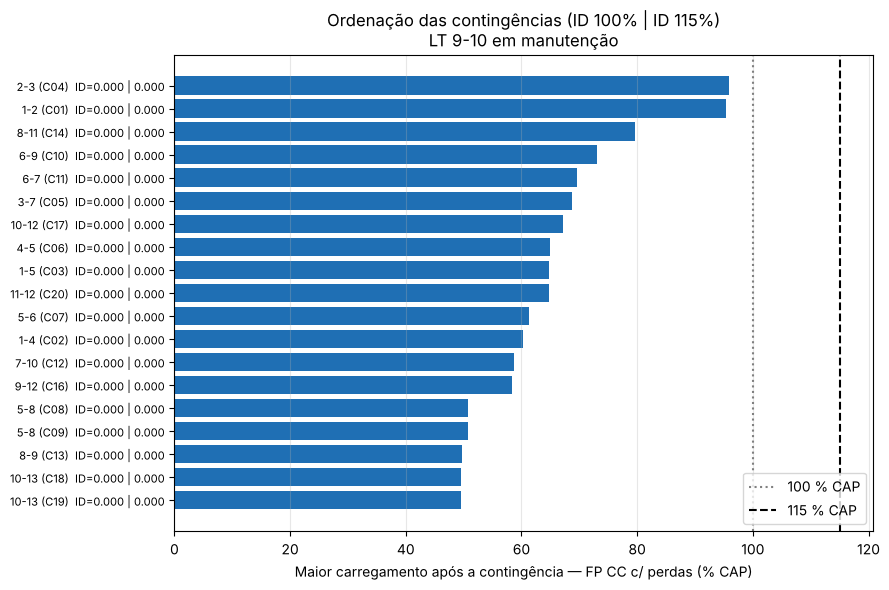


                 3) DIAGNÓSTICO N-1 NÃO LINEAR (NR) — QUESTÃO 1                 

--------------------------------------------------------------------------------
CENÁRIO BASE — Newton-Raphson (limites NORMAIS)
--------------------------------------------------------------------------------
  Convergiu em 4 iterações (erro máx. 1.21e-08 pu)

  Barras:
 Barra Tipo  Nível (kV) V (pu) Vmin (pu) Vmax (pu) Ângulo (°)  PG (MW) QG (MVAr) PD (MW) QD (MVAr) Status
     1   PV         500 1.0200    1.0000    1.1000     2.0468  90.0000   -5.2846  0.0000    0.0000     OK
     2   PQ         500 1.0097    1.0000    1.1000    -0.4601   0.0000    0.0000 75.5200    5.3200     OK
     3   SW         500 1.0200    1.0000    1.1000     0.0000  95.5528   13.4302 72.5100    3.1200     OK
     4   PV         500 1.0200    1.0000    1.1000     0.4395 100.0000   13.5395 89.2200    4.2100     OK
     5   PQ         500 1.0140    1.0000    1.1000     0.1812   0.0000   -0.0000  0.0000    0.0000     OK
     6   

  Iteração  0: 6 violações no N-1 não linear


  Iteração  1: 0 violações no N-1 não linear

--------------------------------------------------------------------------------
Conjunto de ações de controle proposto
--------------------------------------------------------------------------------
          Controle   Mínimo  Máximo Valor (EC2 final) Após linprog CC Final (arredondado) Variação Alterado?
          PG1 (pu)   0.0000  1.2000            0.9000          0.9000              0.9000   0.0000         -
          PG4 (pu)   0.0000  1.0000            1.0000          1.0000              1.0000   0.0000         -
          PG7 (pu)   0.0000  0.8000            0.6000          0.6000              0.6000   0.0000         -
         PG13 (pu)   0.0000  0.8000            0.4000          0.4000              0.4000   0.0000         -
           V1 (pu)   1.0000  1.1000            1.0200          1.0200              1.0200   0.0000         -
           V3 (pu)   1.0000  1.1000            1.0200          1.0200              1.0200   0.0000 


--------------------------------------------------------------------------------
CENÁRIO 5-8 (C09) — Newton-Raphson (limites de EMERGÊNCIA)
--------------------------------------------------------------------------------
  Convergiu em 4 iterações (erro máx. 4.70e-09 pu)

  Barras:
 Barra Tipo  Nível (kV) V (pu) Vmin (pu) Vmax (pu) Ângulo (°)  PG (MW) QG (MVAr) PD (MW) QD (MVAr) Status
     1   PV         500 1.0200    0.9500    1.1000     2.0811  90.0000   -5.3129  0.0000    0.0000     OK
     2   PQ         500 1.0098    0.9500    1.1000    -0.4521   0.0000    0.0000 75.5200    5.3200     OK
     3   SW         500 1.0200    0.9500    1.1000     0.0000  95.4544   13.3601 72.5100    3.1200     OK
     4   PV         500 1.0200    0.9500    1.1000     0.4866 100.0000   13.6560 89.2200    4.2100     OK
     5   PQ         500 1.0140    0.9500    1.1000     0.2314   0.0000   -0.0000  0.0000    0.0000     OK
     6   PQ         500 1.0057    0.9500    1.1000     0.0585   0.0000    0.0000

 Ordem Contingência  NCIR ID (100%) ID (115%) Maior carreg. (%) Circuitos > 100% Circuitos > 115%
     1    2-3 (C04)     4    0.0000    0.0000           95.7894                -                -
     2    1-2 (C01)     1    0.0000    0.0000           95.3315                -                -
     3   8-11 (C14)    14    0.0000    0.0000           79.5873                -                -
     4    6-9 (C10)    10    0.0000    0.0000           73.0339                -                -
     5    6-7 (C11)    11    0.0000    0.0000           69.5648                -                -
     6    3-7 (C05)     5    0.0000    0.0000           68.6814                -                -
     7  10-12 (C17)    17    0.0000    0.0000           67.2587                -                -
     8    4-5 (C06)     6    0.0000    0.0000           65.0132                -                -
     9    1-5 (C03)     3    0.0000    0.0000           64.7756                -                -
    10  11-12 (C20) 

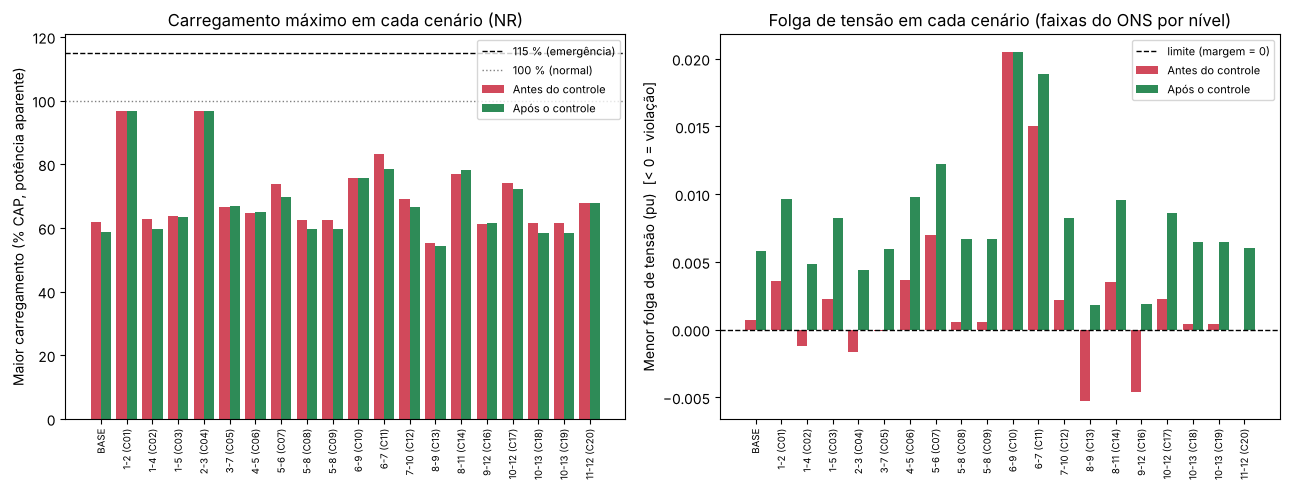


Arquivos gerados na pasta 'resultados_EC3/'.


In [11]:
ec3 = main_ec3()